In [8]:
!nvidia-smi
# Run once in terminal:
!pip install transformers>=4.41.0 torchmetrics albumentations scipy

Fri Apr 10 16:31:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.126.09             Driver Version: 580.126.09     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GB10                    On  |   0000000F:01:00.0  On |                  N/A |
| N/A   47C    P0             12W /  N/A  | Not Supported          |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
!ls /home/user1/jupyterlab/dataset1/images | wc -l
!ls /home/user1/jupyterlab/dataset1/masks | wc -l

8503
8503


In [9]:
!nvidia-smi
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")

Fri Apr 10 16:31:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.126.09             Driver Version: 580.126.09     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GB10                    On  |   0000000F:01:00.0  On |                  N/A |
| N/A   46C    P0             12W /  N/A  | Not Supported          |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CELL 2 — Config
Changes vs previous version:
focal_gamma      : 3.0  → 2.0   (standard validated value; 3.0 over-focuses on noise)
  label_smoothing  : 0.1  → 0.05  (keep mild anti-overconfidence; avoid conflict with focal)
  boundary_weight  : 0.2  → 0.1   (reduce edge over-emphasis; introduced late in training)
   focal_weight     : 0.4  → 0.5   (rebalance now that boundary is halved)
   dice_weight      : 0.4  → 0.4   (unchanged)
   boundary_warmup  : new  → 15    (boundary loss only activates after epoch 15)

In [10]:
import os
import torch

DATASET_ROOT   = "/home/user1/jupyterlab/dataset1"
CHECKPOINT_DIR = "/home/user1/jupyterlab/segformer_ckpts1"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

IMAGE_DIR = os.path.join(DATASET_ROOT, "images")
MASK_DIR  = os.path.join(DATASET_ROOT, "masks")

img_files  = sorted([f for f in os.listdir(IMAGE_DIR) if f.endswith(".png")])
mask_files = sorted([f for f in os.listdir(MASK_DIR)  if f.endswith(".png")])
print(f"Images: {len(img_files)} | Masks: {len(mask_files)}")
assert len(img_files) == len(mask_files)
print("Dataset OK ✓")

CFG = {
    "num_classes"      : 6,
    "image_size"       : 512,
    "crop_size"        : 448,       # RandomCrop to break edge-position bias
    "num_workers"      : 6,

    "backbone"         : "nvidia/mit-b3",

    "epochs"           : 65,
    "batch_size"       : 8,
    "grad_accum_steps" : 2,
    "lr"               : 1.5e-4,
    "weight_decay"     : 0.01,
    "warmup_epochs"    : 0,

    # Loss weights — rebalanced now that boundary_weight is halved
    "focal_weight"     : 0.5,
    "dice_weight"      : 0.4,
    "boundary_weight"  : 0.1,       # FIX: was 0.2 — reduced to avoid over-emphasising edges

    # Focal loss
    # FIX: gamma reduced from 3.0 to 2.0 — original paper default, avoids over-fitting noise
    "focal_gamma"      : 2.0,
    # FIX: smoothing reduced from 0.1 to 0.05 — mild anti-overconfidence, less conflict with focal
    "label_smoothing"  : 0.05,

    # Boundary loss warmup — only activates after this epoch
    # FIX: new setting — model must learn basic regions before edge refinement is useful
    "boundary_warmup_epoch" : 15,

    "val_ratio"        : 0.10,
    "test_ratio"       : 0.10,
    "seed"             : 42,

    # Composite best-model score weights
    # FIX: replaces min(rare_IoU) criterion — balances overall quality with rare-class improvement
    "score_miou_w"     : 0.6,
    "score_rare_w"     : 0.4,

    "checkpoint_dir"   : CHECKPOINT_DIR,
    "resume_ckpt"      : None,

    "device"           : "cuda" if torch.cuda.is_available() else "cpu",
    "use_amp"          : True,
}

ID2LABEL = {
    0: "Background",
    1: "Building",
    2: "Road",
    3: "Water",
    4: "Bridge",
    5: "Utility",
}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

CLASS_COLORS = {
    0: (80,  80,  80),
    1: (230, 76,  60),
    2: (250, 200, 50),
    3: (60,  130, 220),
    4: (255, 140, 0),
    5: (80,  200, 120),
}

print(f"Device: {CFG['device']}")
if CFG["device"] == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
    try:
        vram = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f"VRAM  : {vram:.1f} GB")
    except:
        print("VRAM  : Unified memory (GB10 — shared with CPU)")
print("Cell 2 complete ✓")



Images: 8503 | Masks: 8503
Dataset OK ✓
Device: cuda
GPU   : NVIDIA GB10
VRAM  : 128.5 GB
Cell 2 complete ✓


 CELL 3 — Splits + pixel counts + class weights
 Changes vs previous version:
  class_weights  : Bridge=35, Utility=25, Water=15 (uncapped)
                  → Bridge=8,  Utility=6,  Water=4  (capped at safe range)
                    Focal already up-weights hard pixels via (1-p)^gamma;
                   stacking 35x on top causes gradient explosion.
   Background     : 0.15 → 0.30 — too-aggressive suppression loses
                    boundary context that defines all other classes.
   DICE weights   : removed entirely — Dice already handles class
                    imbalance via intersection/union; separate Dice weights
                    create conflicting optimization signal vs focal weights.

In [11]:
import numpy as np
import json
from PIL import Image
from tqdm import tqdm
import random

splits_path     = os.path.join(CFG["checkpoint_dir"], "splits.json")
pixelcount_path = os.path.join(CFG["checkpoint_dir"], "pixel_counts.npy")

RARE_CLASSES  = [4, 5]   # Bridge, Utility
BRIDGE_CLASS  = 4
UTILITY_CLASS = 5

# ── SPLITS ───────────────────────────────────────────────────
if os.path.exists(splits_path):
    print("Loading splits from Drive...")
    with open(splits_path) as f:
        splits = json.load(f)
    train_ids = splits["train"]
    val_ids   = splits["val"]
    test_ids  = splits["test"]

else:
    print("Computing splits...")

    all_ids = [os.path.splitext(f)[0] for f in os.listdir(IMAGE_DIR)
               if f.endswith(".png")]

    # ── Identify rare-class images ────────────────────────────
    bridge_ids  = []
    utility_ids = []
    common_ids  = []

    for fid in tqdm(all_ids, desc="Scanning masks"):
        mask = np.array(Image.open(os.path.join(MASK_DIR, f"{fid}.png")))
        has_bridge  = (mask == BRIDGE_CLASS).any()
        has_utility = (mask == UTILITY_CLASS).any()
        if has_bridge:
            bridge_ids.append(fid)
        elif has_utility:
            utility_ids.append(fid)
        else:
            common_ids.append(fid)

    print(f"Bridge images  : {len(bridge_ids)}")
    print(f"Utility images : {len(utility_ids)}")
    print(f"Common images  : {len(common_ids)}")

    random.seed(CFG["seed"])
    random.shuffle(common_ids)

    # Split common ids 80/10/10
    n_val  = int(len(common_ids) * CFG["val_ratio"])
    n_test = int(len(common_ids) * CFG["test_ratio"])
    val_ids   = common_ids[:n_val]
    test_ids  = common_ids[n_val:n_val + n_test]
    train_ids = common_ids[n_val + n_test:]

    # Distribute bridge: 80 train / 10 val / 10 test
    for ids_list, frac in [(train_ids, 0.80), (val_ids, 0.10), (test_ids, 0.10)]:
        n = max(1, int(len(bridge_ids) * frac))
        ids_list.extend(bridge_ids[:n])
        bridge_ids = bridge_ids[n:]
    train_ids.extend(bridge_ids)   # any remainder → train

    # Distribute utility: same split
    for ids_list, frac in [(train_ids, 0.80), (val_ids, 0.10), (test_ids, 0.10)]:
        n = max(1, int(len(utility_ids) * frac))
        ids_list.extend(utility_ids[:n])
        utility_ids = utility_ids[n:]
    train_ids.extend(utility_ids)

    splits = {"train": train_ids, "val": val_ids, "test": test_ids}
    with open(splits_path, "w") as f:
        json.dump(splits, f)
    print(f"Splits saved → {splits_path}")

print(f"Train: {len(train_ids)} | Val: {len(val_ids)} | Test: {len(test_ids)}")

# Verify rare class presence in val
bridge_in_val  = sum(1 for fid in val_ids
    if (np.array(Image.open(os.path.join(MASK_DIR, f"{fid}.png"))) == BRIDGE_CLASS).any())
utility_in_val = sum(1 for fid in val_ids
    if (np.array(Image.open(os.path.join(MASK_DIR, f"{fid}.png"))) == UTILITY_CLASS).any())
print(f"Bridge in val: {bridge_in_val} | Utility in val: {utility_in_val}")

# ── PIXEL COUNTS ─────────────────────────────────────────────
if os.path.exists(pixelcount_path):
    print("Loading pixel counts from Drive...")
    pixel_counts = np.load(pixelcount_path)
else:
    print("Counting pixels...")
    pixel_counts = np.zeros(CFG["num_classes"], dtype=np.float64)
    for fid in tqdm(train_ids):
        mask = np.array(Image.open(os.path.join(MASK_DIR, f"{fid}.png")))
        for c in range(CFG["num_classes"]):
            pixel_counts[c] += (mask == c).sum()
    np.save(pixelcount_path, pixel_counts)

print("\nPixel distribution:")
for c in range(CFG["num_classes"]):
    pct = 100 * pixel_counts[c] / pixel_counts.sum()
    print(f"  [{c}] {ID2LABEL[c]:12s}: {pct:.2f}%")

# ── CLASS WEIGHTS ─────────────────────────────────────────────
total       = pixel_counts.sum()
raw_weights = total / (CFG["num_classes"] * pixel_counts + 1e-6)
raw_weights = raw_weights / raw_weights.mean()

# Option B: mild inverse frequency only — focal handles the rest
# No manual overrides, no aggressive caps
# Clip range 0.5–3.0 so no class gets more than 3x another
class_weights = np.clip(raw_weights, 0.5, 3.0)

class_weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32
).to(CFG["device"])

print("\nRaw weights   :", np.round(raw_weights, 2))
print("Final weights :", np.round(class_weights, 2))
print("(Focal loss handles hard pixel emphasis — class weights are mild guidance only)")
print("\nCell 3 complete ✓")

Computing splits...


Scanning masks: 100%|██████████| 8503/8503 [00:04<00:00, 2114.35it/s]


Bridge images  : 29
Utility images : 757
Common images  : 7717
Splits saved → /home/user1/jupyterlab/segformer_ckpts1/splits.json
Train: 6931 | Val: 787 | Test: 785
Bridge in val: 1 | Utility in val: 15
Counting pixels...


100%|██████████| 6931/6931 [00:07<00:00, 986.48it/s]



Pixel distribution:
  [0] Background  : 60.26%
  [1] Building    : 23.95%
  [2] Road        : 9.75%
  [3] Water       : 5.94%
  [4] Bridge      : 0.02%
  [5] Utility     : 0.08%

Raw weights   : [0.   0.   0.01 0.02 4.68 1.28]
Final weights : [0.5  0.5  0.5  0.5  3.   1.28]
(Focal loss handles hard pixel emphasis — class weights are mild guidance only)

Cell 3 complete ✓


 =============================================================
 CELL 4 — Augmentation + Dataset + DataLoader
 =============================================================
 Changes vs previous version:
   Photometric   : ColorJitter + HueSaturationValue wrapped in A.OneOf()
                   so at most one strong colour transform applies per image.
                   Previously both could stack (combined probability ~28%).
   Structural    : ElasticTransform removed — distorts road connectivity,
                   teaching the model that broken roads are normal.
                   GridDistortion kept but distort_limit halved (0.2→0.1).
   Sampler boost : pixel-ratio formula capped at 5x (was 12x).
                   12x repetition of ~20 bridge images → severe overfitting
                   to those specific tile backgrounds. 5x is the safe ceiling.

In [13]:
# =============================================================
# CELL 4 — Augmentation + Dataset + DataLoader
# Option B: sampler REMOVED — focal loss handles class imbalance
# Sampler + focal was double-counting, causing gradient variance
# =============================================================

import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),

    A.RandomCrop(height=CFG["crop_size"], width=CFG["crop_size"], p=0.5),
    A.Resize(CFG["image_size"], CFG["image_size"]),

    A.OneOf([
        A.ColorJitter(
            brightness=0.4, contrast=0.4,
            saturation=0.3, hue=0.1,
        ),
        A.HueSaturationValue(
            hue_shift_limit=20,
            sat_shift_limit=30,
            val_shift_limit=20,
        ),
    ], p=0.7),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.4,
    ),

    A.RandomShadow(p=0.3),

    A.GaussianBlur(blur_limit=3, p=0.3),
    A.GaussNoise(p=0.3),
    A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=0.2),

    A.GridDistortion(num_steps=5, distort_limit=0.1, p=0.1),

    A.CoarseDropout(
        num_holes_range=(1, 4),
        hole_height_range=(8, 24),
        hole_width_range=(8, 24),
        fill=0,
        fill_mask=255,
        p=0.2
    ),

    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
],
# bmap declared so ALL geometric transforms apply identically
# to boundary map and mask — no spatial misalignment
additional_targets={"mask": "mask", "bmap": "mask"})

val_transform = A.Compose([
    A.Resize(CFG["image_size"], CFG["image_size"]),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
], additional_targets={"mask": "mask"})


class SegDataset(Dataset):
    def __init__(self, ids, image_dir, mask_dir, transform=None):
        self.ids       = ids
        self.image_dir = image_dir
        self.mask_dir  = mask_dir
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        fid   = self.ids[idx]
        image = np.array(
            Image.open(os.path.join(
                self.image_dir, f"{fid}.png")).convert("RGB")
        )
        mask = np.array(
            Image.open(os.path.join(self.mask_dir, f"{fid}.png"))
        )
        mask = np.clip(mask, 0, CFG["num_classes"] - 1).astype(np.int64)

        if self.transform:
            aug   = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask  = aug["mask"]

        return image, mask.long(), torch.from_numpy(bmap)


train_ds = SegDataset(train_ids, IMAGE_DIR, MASK_DIR, train_transform)
val_ds   = SegDataset(val_ids,   IMAGE_DIR, MASK_DIR, val_transform)
test_ds  = SegDataset(test_ids,  IMAGE_DIR, MASK_DIR, val_transform)

# Standard shuffle — no weighted sampler
train_loader = DataLoader(
    train_ds,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=CFG["num_workers"],
    pin_memory=False,
    drop_last=True,
)
val_loader = DataLoader(
    val_ds,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=False,
)
test_loader = DataLoader(
    test_ds,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=False,
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches  : {len(val_loader)}")
print(f"Test batches : {len(test_loader)}")
print("Cell 4 complete ✓")

Train batches: 866
Val batches  : 99
Test batches : 99
Cell 4 complete ✓


 =============================================================
 CELL 5 — Loss Functions
=============================================================
 Changes vs previous version:
   FocalLoss     : gamma 3.0→2.0, label_smoothing 0.1→0.05
   DiceLoss      : per-class weights REMOVED — standard unweighted mean Dice.
                   Reason: Dice already handles imbalance via IoU formulation.
                   Separate Dice weights (misaligned with focal weights) create
                   conflicting gradient signals between the two loss terms.
   BoundaryLoss  : CPU→GPU fix — weight map pre-computed per sample in Dataset
                   __getitem__ so distance_transform never runs inside forward().
                   This removes the per-batch CPU transfer that added ~30-60ms/batch.
                   Training loop passes boundary_weights tensor alongside masks.
   CombinedLoss  : boundary_w 0.2→0.1, focal_w 0.4→0.5 (rebalanced).
                   Boundary loss activates only after boundary_warmup_epoch (15).

In [14]:
# =============================================================
# CELL 5 — Loss Functions
# Option B: Focal + Dice + Boundary
# Sampler removed so focal is the ONLY mechanism handling
# class imbalance — gamma=2.0, mild class weights 0.5-3x
# Gradient normalised by weighted pixel count not plain mean
# Boundary: linear ramp, not hard switch
# =============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class FocalLoss(nn.Module):
    """
    Focal loss with gradient normalisation.
    Normalises by weighted pixel count so batches with different
    class distributions produce comparable gradient magnitudes.
    This directly addresses the 30,000x gradient variance problem.
    """
    def __init__(self, weight=None, gamma=2.0, ignore_index=255,
                 label_smoothing=0.05):
        super().__init__()
        self.weight          = weight
        self.gamma           = gamma
        self.ignore_index    = ignore_index
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(
            logits, targets,
            weight=self.weight,
            ignore_index=self.ignore_index,
            reduction="none",
            label_smoothing=self.label_smoothing,
        )
        pt         = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        valid      = targets != self.ignore_index

        # Gradient normalisation: divide by weighted pixel count
        # so rare-class-heavy batches and background-heavy batches
        # produce the same total gradient magnitude
        if self.weight is not None:
            pixel_weights = self.weight[targets[valid]]
            weight_sum    = pixel_weights.sum().clamp(min=1.0)
            return focal_loss[valid].sum() / weight_sum
        return focal_loss[valid].mean()


class DiceLoss(nn.Module):
    """Standard unweighted Dice — handles region overlap."""
    def __init__(self, num_classes, smooth=1.0, ignore_index=255):
        super().__init__()
        self.num_classes  = num_classes
        self.smooth       = smooth
        self.ignore_index = ignore_index

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        valid = targets != self.ignore_index
        t     = targets.clone()
        t[~valid] = 0

        one_hot    = F.one_hot(t, self.num_classes).permute(0,3,1,2).float()
        valid_mask = valid.unsqueeze(1).float()
        probs      = probs * valid_mask
        one_hot    = one_hot * valid_mask

        dims  = (0, 2, 3)
        inter = (probs * one_hot).sum(dim=dims)
        union = probs.sum(dim=dims) + one_hot.sum(dim=dims)
        dice  = (2.0 * inter + self.smooth) / (union + self.smooth)
        return 1.0 - dice.mean()


class BoundaryLoss(nn.Module):
    """
    Boundary-weighted CE loss.
    Pixels near GT class edges get higher weight — teaches
    the model spatial precision at building edges, road
    boundaries, and water shorelines.
    Pre-computed weight maps passed from DataLoader.
    """
    def __init__(self, ignore_index=255):
        super().__init__()
        self.ignore_index = ignore_index

    def forward(self, logits, targets, boundary_weights):
        ce = F.cross_entropy(
            logits, targets,
            ignore_index=self.ignore_index,
            reduction="none",
        )
        return (ce * boundary_weights).mean()


class CombinedLoss(nn.Module):
    """
    Focal (0.5) + Dice (0.4) + Boundary (0.1).
    Boundary ramps in linearly over 5 epochs after warmup
    to avoid gradient shock.
    LR is halved once at boundary activation epoch.
    """
    def __init__(self, class_weights, num_classes,
                 focal_w=0.5, dice_w=0.4, boundary_w=0.1,
                 focal_gamma=2.0, label_smoothing=0.05,
                 boundary_warmup_epoch=15,
                 ignore_index=255):
        super().__init__()

        self.focal    = FocalLoss(
            weight=class_weights,
            gamma=focal_gamma,
            ignore_index=ignore_index,
            label_smoothing=label_smoothing,
        )
        self.dice     = DiceLoss(
            num_classes=num_classes,
            ignore_index=ignore_index,
        )
        self.boundary = BoundaryLoss(ignore_index=ignore_index)

        self.focal_w               = focal_w
        self.dice_w                = dice_w
        self.boundary_w            = boundary_w
        self.boundary_warmup_epoch = boundary_warmup_epoch
        self.boundary_ramp_epochs  = 5

    def forward(self, logits, targets, boundary_weights, current_epoch):
        l_focal = self.focal(logits, targets)
        l_dice  = self.dice(logits, targets)

        # Linear ramp: 0 → boundary_w over 5 epochs after warmup
        epochs_past = current_epoch - self.boundary_warmup_epoch
        if epochs_past < 0:
            active_bw  = 0.0
            l_boundary = torch.tensor(0.0, device=logits.device)
        else:
            ramp       = min(epochs_past / self.boundary_ramp_epochs, 1.0)
            active_bw  = self.boundary_w * ramp
            l_boundary = self.boundary(logits, targets, boundary_weights)

        # Always renormalise so focal+dice+boundary sum to 1.0
        remaining = 1.0 - active_bw
        total_fd  = self.focal_w + self.dice_w
        f_w = (self.focal_w / total_fd) * remaining
        d_w = (self.dice_w  / total_fd) * remaining

        total = f_w * l_focal + d_w * l_dice + active_bw * l_boundary
        return total, l_focal, l_dice, l_boundary


criterion = CombinedLoss(
    class_weights         = class_weights_tensor,
    num_classes           = CFG["num_classes"],
    focal_w               = CFG["focal_weight"],
    dice_w                = CFG["dice_weight"],
    boundary_w            = CFG["boundary_weight"],
    focal_gamma           = CFG["focal_gamma"],
    label_smoothing       = CFG["label_smoothing"],
    boundary_warmup_epoch = CFG["boundary_warmup_epoch"],
).to(CFG["device"])

print("Loss function ready ✓")
print(f"  Focal    : weight={CFG['focal_weight']} gamma={CFG['focal_gamma']} "
      f"smoothing={CFG['label_smoothing']} (gradient-normalised)")
print(f"  Dice     : weight={CFG['dice_weight']} (unweighted mean)")
print(f"  Boundary : weight={CFG['boundary_weight']} "
      f"(ramps in epochs {CFG['boundary_warmup_epoch']}–"
      f"{CFG['boundary_warmup_epoch']+5})")
print("Cell 5 complete ✓")

Loss function ready ✓
  Focal    : weight=0.5 gamma=2.0 smoothing=0.05 (gradient-normalised)
  Dice     : weight=0.4 (unweighted mean)
  Boundary : weight=0.1 (ramps in epochs 15–20)
Cell 5 complete ✓


 =============================================================
 CELL 5b — Boundary weight map pre-computation
 =============================================================
 FIX: distance_transform_edt used to run inside BoundaryLoss.forward()
 on every training batch — ~30-60ms of CPU work + GPU transfer per batch.
 We now pre-compute boundary weight maps for all training images once,
 cache them to disk, and return them from Dataset.__getitem__.
 Dataset and DataLoader are rebuilt here to include the weight maps.

In [25]:
from transformers import SegformerForSemanticSegmentation
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
model = SegformerForSemanticSegmentation.from_pretrained(
    CFG["backbone"],
    num_labels=CFG["num_classes"],
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True,
    drop_path_rate=0.1
)
model = model.to(CFG["device"])

# Differential LR: backbone 10x lower than decode head
backbone_params = [p for n, p in model.named_parameters()
                   if "segformer.encoder" in n]
head_params     = [p for n, p in model.named_parameters()
                   if "segformer.encoder" not in n]

optimizer = AdamW([
    {"params": backbone_params, "lr": CFG["lr"] * 0.1},
    {"params": head_params,     "lr": CFG["lr"]},
], weight_decay=CFG["weight_decay"])


scheduler = CosineAnnealingWarmRestarts(
    optimizer,
    T_0=20,        # first restart after 20 epochs
    T_mult=2,      # each subsequent cycle doubles in length
    eta_min=1e-6,  # minimum LR at trough
)
# Cycle pattern: 0-20 | 20-60 | 60-65(partial)
# You get 2 full restarts within 65 epochs
# epoch 20 = first LR reset to max
# epoch 60 = second LR reset to max (partial cycle, training ends at 65)
scaler = torch.amp.GradScaler("cuda", enabled=False)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model params : {total_params:.1f}M")
print("Cell 6 complete ✓")

You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 628/628 [00:00<00:00, 35866.33it/s]
SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.weight                             | UNEXPECTED | 
classifier.bias                               | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.bias      

Model params : 47.2M
Cell 6 complete ✓


In [27]:
# =============================================================
# CELL 5b — Boundary weight map pre-computation + Dataset rebuild
# =============================================================

from scipy.ndimage import distance_transform_edt

BOUNDARY_CACHE_DIR = os.path.join(CFG["checkpoint_dir"], "boundary_cache")
os.makedirs(BOUNDARY_CACHE_DIR, exist_ok=True)


def compute_boundary_weight_map(mask_np, ignore_index=255):
    boundary = np.zeros_like(mask_np, dtype=bool)
    for dy, dx in [(-1,0),(1,0),(0,-1),(0,1)]:
        shifted  = np.roll(mask_np, (dy, dx), axis=(0,1))
        boundary |= (mask_np != shifted)
    boundary[mask_np == ignore_index] = False
    dist   = distance_transform_edt(~boundary).astype(np.float32)
    weight = 1.0 / (1.0 + dist * 0.1)
    return weight


def precompute_boundary_maps(ids, mask_dir, cache_dir):
    missing = [fid for fid in ids
               if not os.path.exists(
                   os.path.join(cache_dir, f"{fid}.npy"))]
    if not missing:
        print(f"Boundary maps already cached ({len(ids)} total) ✓")
        return
    print(f"Pre-computing {len(missing)} boundary maps...")
    for fid in tqdm(missing, desc="Boundary maps"):
        mask = np.array(Image.open(
            os.path.join(mask_dir, f"{fid}.png")))
        mask = np.clip(mask, 0, CFG["num_classes"]-1).astype(np.int64)
        np.save(os.path.join(cache_dir, f"{fid}.npy"),
                compute_boundary_weight_map(mask))
    print("Boundary maps cached ✓")


# Cache invalidation — clears if train split changed between runs
cache_info_path = os.path.join(BOUNDARY_CACHE_DIR, "cache_info.json")
current_info    = {"train_count": len(train_ids), "seed": CFG["seed"]}

if os.path.exists(cache_info_path):
    with open(cache_info_path) as f:
        cached_info = json.load(f)
    if cached_info != current_info:
        print("⚠ Train split changed — clearing boundary cache")
        import shutil
        shutil.rmtree(BOUNDARY_CACHE_DIR)
        os.makedirs(BOUNDARY_CACHE_DIR, exist_ok=True)

precompute_boundary_maps(train_ids, MASK_DIR, BOUNDARY_CACHE_DIR)

with open(cache_info_path, "w") as f:
    json.dump(current_info, f)


class SegDatasetWithBoundary(Dataset):
    def __init__(self, ids, image_dir, mask_dir, transform=None,
                 boundary_cache_dir=None, use_boundary=True):
        self.ids                = ids
        self.image_dir          = image_dir
        self.mask_dir           = mask_dir
        self.transform          = transform
        self.boundary_cache_dir = boundary_cache_dir
        self.use_boundary       = use_boundary and \
                                  (boundary_cache_dir is not None)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        fid   = self.ids[idx]
        image = np.array(Image.open(
            os.path.join(self.image_dir,
                         f"{fid}.png")).convert("RGB"))
        mask  = np.clip(
            np.array(Image.open(
                os.path.join(self.mask_dir, f"{fid}.png"))),
            0, CFG["num_classes"]-1
        ).astype(np.int64)

        bmap = (np.load(
                    os.path.join(self.boundary_cache_dir, f"{fid}.npy")
                ).astype(np.float32)
                if self.use_boundary
                else np.zeros(mask.shape, dtype=np.float32))

        if self.transform:
            # bmap passed as additional target — receives identical
            # geometric transforms as mask (flip/crop/rotate/distort)
            # eliminates spatial misalignment completely
            aug   = self.transform(image=image, mask=mask, bmap=bmap)
            image = aug["image"]
            mask  = aug["mask"]
            bmap = aug["bmap"]
            if isinstance(bmap, torch.Tensor):
                bmap = bmap.numpy()
            bmap = bmap.astype(np.float32)

        return image, mask.long(), bmap


train_ds = SegDatasetWithBoundary(
    train_ids, IMAGE_DIR, MASK_DIR, train_transform,
    boundary_cache_dir=BOUNDARY_CACHE_DIR, use_boundary=True
)
val_ds = SegDatasetWithBoundary(
    val_ids, IMAGE_DIR, MASK_DIR, val_transform,
    boundary_cache_dir=None, use_boundary=False
)
test_ds = SegDatasetWithBoundary(
    test_ids, IMAGE_DIR, MASK_DIR, val_transform,
    boundary_cache_dir=None, use_boundary=False
)

train_loader = DataLoader(
    train_ds, batch_size=CFG["batch_size"],
    shuffle=True,                   # no sampler — focal handles imbalance
    num_workers=CFG["num_workers"],
    pin_memory=False, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=CFG["batch_size"],
    shuffle=False, num_workers=CFG["num_workers"], pin_memory=False,
)
test_loader = DataLoader(
    test_ds, batch_size=CFG["batch_size"],
    shuffle=False, num_workers=CFG["num_workers"], pin_memory=False,
)

# Loss magnitude check before training starts
# Replace lines 739-754 with:
print("Checking focal/dice magnitude balance...")
_img, _msk, _bw = next(iter(train_loader))
with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.bfloat16,
                                          enabled=CFG["use_amp"]):
    _out = model(pixel_values=_img.to(CFG["device"]))
    _log = F.interpolate(_out.logits, size=_msk.shape[-2:],
                         mode="bilinear", align_corners=False)
    _, _lf, _ld, _ = criterion(
        _log, _msk.to(CFG["device"]),
        _bw.to(CFG["device"]), current_epoch=999
    )
_ratio = _lf.item() / (_ld.item() + 1e-8)
print(f"  focal={_lf.item():.4f}  dice={_ld.item():.4f}  ratio={_ratio:.2f}")
if _ratio > 5 or _ratio < 0.2:
    print(f"  ⚠ Magnitude imbalance — adjust focal_weight/dice_weight")
else:
    print(f"  ✓ Loss magnitudes balanced")

print(f"Train: {len(train_loader)} | Val: {len(val_loader)} | "
      f"Test: {len(test_loader)}")
print("Cell 5b complete ✓")

Boundary maps already cached (6931 total) ✓
Checking focal/dice magnitude balance...
  focal=0.7309  dice=0.8914  ratio=0.82
  ✓ Loss magnitudes balanced
Train: 866 | Val: 99 | Test: 99
Cell 5b complete ✓


CELL 6 — Model + Optimizer

 Plain SegformerForSemanticSegmentation — no auxiliary heads.
 model(pixel_values=...) returns a SegformerSemanticSegmenterOutput;
 logits are accessed via outputs.logits, shape (B, num_classes, H/4, W/4).

 Differential LR:
   segformer.encoder  → 0.1 × base LR  (pretrained MiT backbone)
   decode_head        → 1.0 × base LR  (randomly initialised head)
 This is the standard SegFormer fine-tuning setup from the original paper.

In [20]:
print(model.config.num_labels)

6


# CELL 7 — Metrics

In [28]:
from torchmetrics import JaccardIndex, Accuracy

iou_metric = JaccardIndex(
    task="multiclass",
    num_classes=CFG["num_classes"],
    average="none",
    ignore_index=255,
).to(CFG["device"])

acc_metric = Accuracy(
    task="multiclass",
    num_classes=CFG["num_classes"],
    ignore_index=255,
).to(CFG["device"])

print("Metrics ready ✓")

Metrics ready ✓


# CELL 8 — Checkpoint helpers

In [29]:
def save_checkpoint(epoch, model, optimizer, scheduler, scaler,
                    best_score, history, path):
    torch.save({
        "epoch"      : epoch,
        "model"      : model.state_dict(),
        "optimizer"  : optimizer.state_dict(),
        "scheduler"  : scheduler.state_dict(),
        "scaler"     : scaler.state_dict(),
        "best_score" : best_score,
        "history"    : history,
        "cfg"        : CFG,
    }, path)
    print(f"  → Saved: {os.path.basename(path)}")


def load_checkpoint(path, model, optimizer, scheduler, scaler):
    ckpt = torch.load(path, map_location=CFG["device"])
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    best_score = ckpt.get("best_score", 0.0)
    print(f"Resumed from epoch {ckpt['epoch']} | best score={best_score:.4f}")
    return ckpt["epoch"], best_score, ckpt.get("history", [])


def get_latest_checkpoint(ckpt_dir):
    ckpts = [f for f in os.listdir(ckpt_dir)
             if f.startswith("epoch_") and f.endswith(".pth")]
    if not ckpts:
        return None
    ckpts = sorted(ckpts, key=lambda x: int(x.split("_")[1].split(".")[0]))
    return os.path.join(ckpt_dir, ckpts[-1])


print("Checkpoint helpers ready ✓")

Checkpoint helpers ready ✓


# CELL 9 — Training loop
Changes vs previous version:
  Best-model criterion:
    FIX: uses validation mIoU directly for model selection.
    Rationale: mIoU is stable and reflects overall segmentation quality.
    Avoids randomness from rare-class fluctuations (e.g., Bridge IoU spikes).

  Loss component monitoring:
    Each loss component (focal, dice, boundary) is tracked and printed
    every epoch. If any component exceeds 3x its epoch-1 value, a
    warning is printed — signals instability before it compounds.

  Train loop:
    DataLoader yields (images, masks, boundary_weights).
    current_epoch passed to criterion.forward() for boundary warmup.

In [30]:
import time
import numpy as np
from tqdm import tqdm

# ── Auto-resume ───────────────────────────────────────────────
start_epoch = 0
best_score  = 0.0
history     = []

if CFG["resume_ckpt"] is None:
    latest = get_latest_checkpoint(CFG["checkpoint_dir"])
    if latest:
        CFG["resume_ckpt"] = latest
        print(f"Auto-resuming from: {latest}")

if CFG["resume_ckpt"] and os.path.exists(CFG["resume_ckpt"]):
    start_epoch, best_score, history = load_checkpoint(
        CFG["resume_ckpt"], model, optimizer, scheduler, scaler
    )
    start_epoch += 1
# Tracks epoch-1 loss values for instability detection
_epoch1_losses = {"focal": None, "dice": None, "boundary": None}

RARE_EVAL_CLASSES = [2, 3, 4, 5]   # Road, Water, Bridge, Utility


# ── Train one epoch ───────────────────────────────────────────
def train_one_epoch(epoch):
    model.train()
    iou_metric.reset()
    acc_metric.reset()

    # LR halving at boundary activation — reduces shock from
    # new gradient direction entering at epoch 15

    running_loss = running_focal = running_dice = running_boundary = 0.0
    optimizer.zero_grad()

    # rest of your existing train_one_epoch code unchanged...
    # DataLoader now yields 3 items: images, masks, boundary_weights
    for step, (images, masks, bweights) in enumerate(
            tqdm(train_loader, desc=f"Epoch {epoch+1} train", leave=True)):

        images   = images.to(CFG["device"],   non_blocking=True)
        masks    = masks.to(CFG["device"],    non_blocking=True)
        bweights = bweights.to(CFG["device"], non_blocking=True)

        with torch.amp.autocast("cuda",
                         dtype=torch.bfloat16,
                         enabled=CFG["use_amp"]):
            outputs    = model(pixel_values=images)
            seg_logits = outputs.logits   # (B, num_classes, H/4, W/4)

            logits_up = F.interpolate(
                seg_logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )

            loss, l_f, l_d, l_b = criterion(
                logits_up, masks, bweights, current_epoch=epoch
            )
            loss = loss / CFG["grad_accum_steps"]

        scaler.scale(loss).backward()
        running_loss     += loss.item() * CFG["grad_accum_steps"]
        running_focal    += l_f.item()
        running_dice     += l_d.item()
        running_boundary += l_b.item()

        if (step + 1) % CFG["grad_accum_steps"] == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        with torch.no_grad():
            preds = logits_up.argmax(dim=1)
            iou_metric.update(preds, masks)
            acc_metric.update(preds, masks)

    n = len(train_loader)
    per_class_iou = iou_metric.compute().cpu().numpy()
    return (
        running_loss / n,
        running_focal / n,
        running_dice / n,
        running_boundary / n,
        per_class_iou.mean(),
        acc_metric.compute().item(),
        per_class_iou,
    )


# ── Validate ──────────────────────────────────────────────────
@torch.no_grad()
def validate(loader, split="val"):
    model.eval()
    iou_metric.reset()
    acc_metric.reset()
    running_loss = 0.0

    # Val/test loaders also yield 3 items (bweights are zeros)
    for images, masks, bweights in tqdm(loader, desc=f"  {split}", leave=True):
        images   = images.to(CFG["device"],   non_blocking=True)
        masks    = masks.to(CFG["device"],    non_blocking=True)
        bweights = bweights.to(CFG["device"], non_blocking=True)

        with torch.amp.autocast("cuda",
                         dtype=torch.bfloat16,
                         enabled=CFG["use_amp"]):
            outputs    = model(pixel_values=images)
            seg_logits = outputs.logits   # (B, num_classes, H/4, W/4)
            logits_up = F.interpolate(
                seg_logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            loss, _, _, _ = criterion(logits_up, masks, bweights, current_epoch=999)

        running_loss += loss.item()
        preds = logits_up.argmax(dim=1)
        iou_metric.update(preds, masks)
        acc_metric.update(preds, masks)

    per_class_iou = iou_metric.compute().cpu().numpy()
    return (
        running_loss / len(loader),
        per_class_iou.mean(),
        acc_metric.compute().item(),
        per_class_iou,
    )


# ── Main loop ─────────────────────────────────────────────────
print("=" * 60)
print("Starting training...")
print(f"Boundary loss activates at epoch {CFG['boundary_warmup_epoch']}")
print(f"Best-model criterion: {CFG['score_miou_w']}×mIoU + {CFG['score_rare_w']}×mean(rare IoU)")
print("=" * 60)

for epoch in range(start_epoch, CFG["epochs"]):
    t0 = time.time()

    (tr_loss, tr_focal, tr_dice, tr_boundary,
     tr_miou, tr_acc, tr_iou) = train_one_epoch(epoch)

    vl_loss, vl_miou, vl_acc, vl_iou = validate(val_loader, "val")
    scheduler.step()
    elapsed = time.time() - t0

    # ── Composite score (FIX: replaces min rare IoU) ───────────
    current_score = vl_miou

    # ── Rare class mean for logging ────────────────────────────
    rare_vals      = [vl_iou[c] for c in RARE_EVAL_CLASSES if not np.isnan(vl_iou[c])]
    mean_rare_iou  = float(np.mean(rare_vals)) if rare_vals else 0.0

    # ── Instability warning ────────────────────────────────────
    if epoch == 0:
        _epoch1_losses["focal"]    = tr_focal
        _epoch1_losses["dice"]     = tr_dice
        _epoch1_losses["boundary"] = tr_boundary if tr_boundary > 0 else None
    else:
        for name, val in [("focal", tr_focal), ("dice", tr_dice), ("boundary", tr_boundary)]:
            ref = _epoch1_losses[name]
            if ref and ref > 0 and val > 3.0 * ref:
                print(f"  ⚠ WARNING: {name} loss ({val:.4f}) is >3x its epoch-1 value "
                      f"({ref:.4f}) — possible instability!")

    row = {
        "epoch"        : epoch + 1,
        "tr_loss"      : tr_loss,
        "tr_focal"     : tr_focal,
        "tr_dice"      : tr_dice,
        "tr_boundary"  : tr_boundary,
        "tr_miou"      : tr_miou,
        "tr_acc"       : tr_acc,
        "vl_loss"      : vl_loss,
        "vl_miou"      : vl_miou,
        "vl_acc"       : vl_acc,
        "vl_iou"       : vl_iou.tolist(),
        "mean_rare_iou": mean_rare_iou,
        "composite_score": current_score,
        "time_s"       : elapsed,
        "boundary_active": epoch >= CFG["boundary_warmup_epoch"],
    }
    history.append(row)

    boundary_tag = "ON" if epoch >= CFG["boundary_warmup_epoch"] else f"off (activates ep{CFG['boundary_warmup_epoch']})"

    print(f"\nEpoch {epoch+1:02d}/{CFG['epochs']} — {elapsed/60:.1f} min")
    print(f"  Train  loss={tr_loss:.4f}  "
          f"(focal={tr_focal:.3f}  dice={tr_dice:.3f}  boundary={tr_boundary:.3f} [{boundary_tag}])")
    print(f"  Train  mIoU={tr_miou:.4f}  acc={tr_acc:.4f}")
    print(f"  Val    loss={vl_loss:.4f}  mIoU={vl_miou:.4f}  acc={vl_acc:.4f}")
    print(f"  Val    mean rare IoU={mean_rare_iou:.4f}  mIoU score={current_score:.4f}")

    print("  Val IoU per class:")
    for c in range(CFG["num_classes"]):
        marker = " ★" if c in RARE_EVAL_CLASSES else ""
        iou_v  = vl_iou[c]
        bar    = "█" * int(iou_v * 20) if not np.isnan(iou_v) else "N/A"
        print(f"    [{c}] {ID2LABEL[c]:12s}: {iou_v:.4f}  {bar}{marker}")

    # ── Save epoch checkpoint ──────────────────────────────────
    epoch_ckpt = os.path.join(CFG["checkpoint_dir"], f"epoch_{epoch+1:02d}.pth")
    save_checkpoint(epoch, model, optimizer, scheduler, scaler,
                    best_score, history, epoch_ckpt)

    # ── Save best model — mIoU ────────────────────────────────
    if current_score > best_score:
        best_score = current_score
        best_path  = os.path.join(CFG["checkpoint_dir"], "best_model.pth")
        save_checkpoint(epoch, model, optimizer, scheduler, scaler,
                        best_score, history, best_path)
        print(f"  ★ New best — mIoU={best_score:.4f}")

    # ── Clean old checkpoints (keep last 3) ────────────────────
    old_ckpts = sorted([
        f for f in os.listdir(CFG["checkpoint_dir"])
        if f.startswith("epoch_") and f.endswith(".pth")
    ])
    for old in old_ckpts[:-3]:
        os.remove(os.path.join(CFG["checkpoint_dir"], old))

print("\nTraining complete!")
print(f"Best composite score : {best_score:.4f}")

Starting training...
Boundary loss activates at epoch 15
Best-model criterion: 0.6×mIoU + 0.4×mean(rare IoU)


  val: 100%|██████████| 99/99 [00:21<00:00,  4.57it/s]



Epoch 01/65 — 8.0 min
  Train  loss=0.4277  (focal=0.234  dice=0.670  boundary=0.000 [off (activates ep15)])
  Train  mIoU=0.3749  acc=0.7889
  Val    loss=0.3150  mIoU=0.5034  acc=0.8620
  Val    mean rare IoU=0.3704  mIoU score=0.5034
  Val IoU per class:
    [0] Background  : 0.7962  ███████████████
    [1] Building    : 0.7423  ██████████████
    [2] Road        : 0.5992  ███████████ ★
    [3] Water       : 0.7440  ██████████████ ★
    [4] Bridge      : 0.1321  ██ ★
    [5] Utility     : 0.0064   ★
  → Saved: epoch_01.pth
  → Saved: best_model.pth
  ★ New best — mIoU=0.5034


  val: 100%|██████████| 99/99 [00:21<00:00,  4.61it/s]



Epoch 02/65 — 8.5 min
  Train  loss=0.3772  (focal=0.183  dice=0.620  boundary=0.000 [off (activates ep15)])
  Train  mIoU=0.4693  acc=0.8412
  Val    loss=0.3038  mIoU=0.5330  acc=0.8694
  Val    mean rare IoU=0.4003  mIoU score=0.5330
  Val IoU per class:
    [0] Background  : 0.8023  ████████████████
    [1] Building    : 0.7943  ███████████████
    [2] Road        : 0.6177  ████████████ ★
    [3] Water       : 0.6708  █████████████ ★
    [4] Bridge      : 0.3071  ██████ ★
    [5] Utility     : 0.0056   ★
  → Saved: epoch_02.pth
  → Saved: best_model.pth
  ★ New best — mIoU=0.5330


  val: 100%|██████████| 99/99 [00:21<00:00,  4.64it/s]


... (121 outputs left out)

  val: 100%|██████████| 99/99 [00:22<00:00,  4.45it/s]



Epoch 64/65 — 8.4 min
  Train  loss=0.2516  (focal=0.095  dice=0.491  boundary=0.076 [ON])
  Train  mIoU=0.6959  acc=0.9348
  Val    loss=0.2552  mIoU=0.6820  acc=0.9295
  Val    mean rare IoU=0.5823  mIoU score=0.6820
  Val IoU per class:
    [0] Background  : 0.8899  █████████████████
    [1] Building    : 0.8732  █████████████████
    [2] Road        : 0.7339  ██████████████ ★
    [3] Water       : 0.8992  █████████████████ ★
    [4] Bridge      : 0.5038  ██████████ ★
    [5] Utility     : 0.1922  ███ ★
  → Saved: epoch_64.pth


  val: 100%|██████████| 99/99 [00:22<00:00,  4.48it/s]



Epoch 65/65 — 8.4 min
  Train  loss=0.2496  (focal=0.095  dice=0.486  boundary=0.076 [ON])
  Train  mIoU=0.7093  acc=0.9349
  Val    loss=0.2557  mIoU=0.7182  acc=0.9292
  Val    mean rare IoU=0.6369  mIoU score=0.7182
  Val IoU per class:
    [0] Background  : 0.8896  █████████████████
    [1] Building    : 0.8724  █████████████████
    [2] Road        : 0.7384  ██████████████ ★
    [3] Water       : 0.8797  █████████████████ ★
    [4] Bridge      : 0.7620  ███████████████ ★
    [5] Utility     : 0.1674  ███ ★
  → Saved: epoch_65.pth
  → Saved: best_model.pth
  ★ New best — mIoU=0.7182

Training complete!
Best composite score : 0.7182


Loading checkpoint: /home/user1/jupyterlab/segformer_ckpts1/best_model.pth
Model loaded — best mIoU was: 0.7182457447052002
Evaluating 10 test images...
Inference complete on 10 images


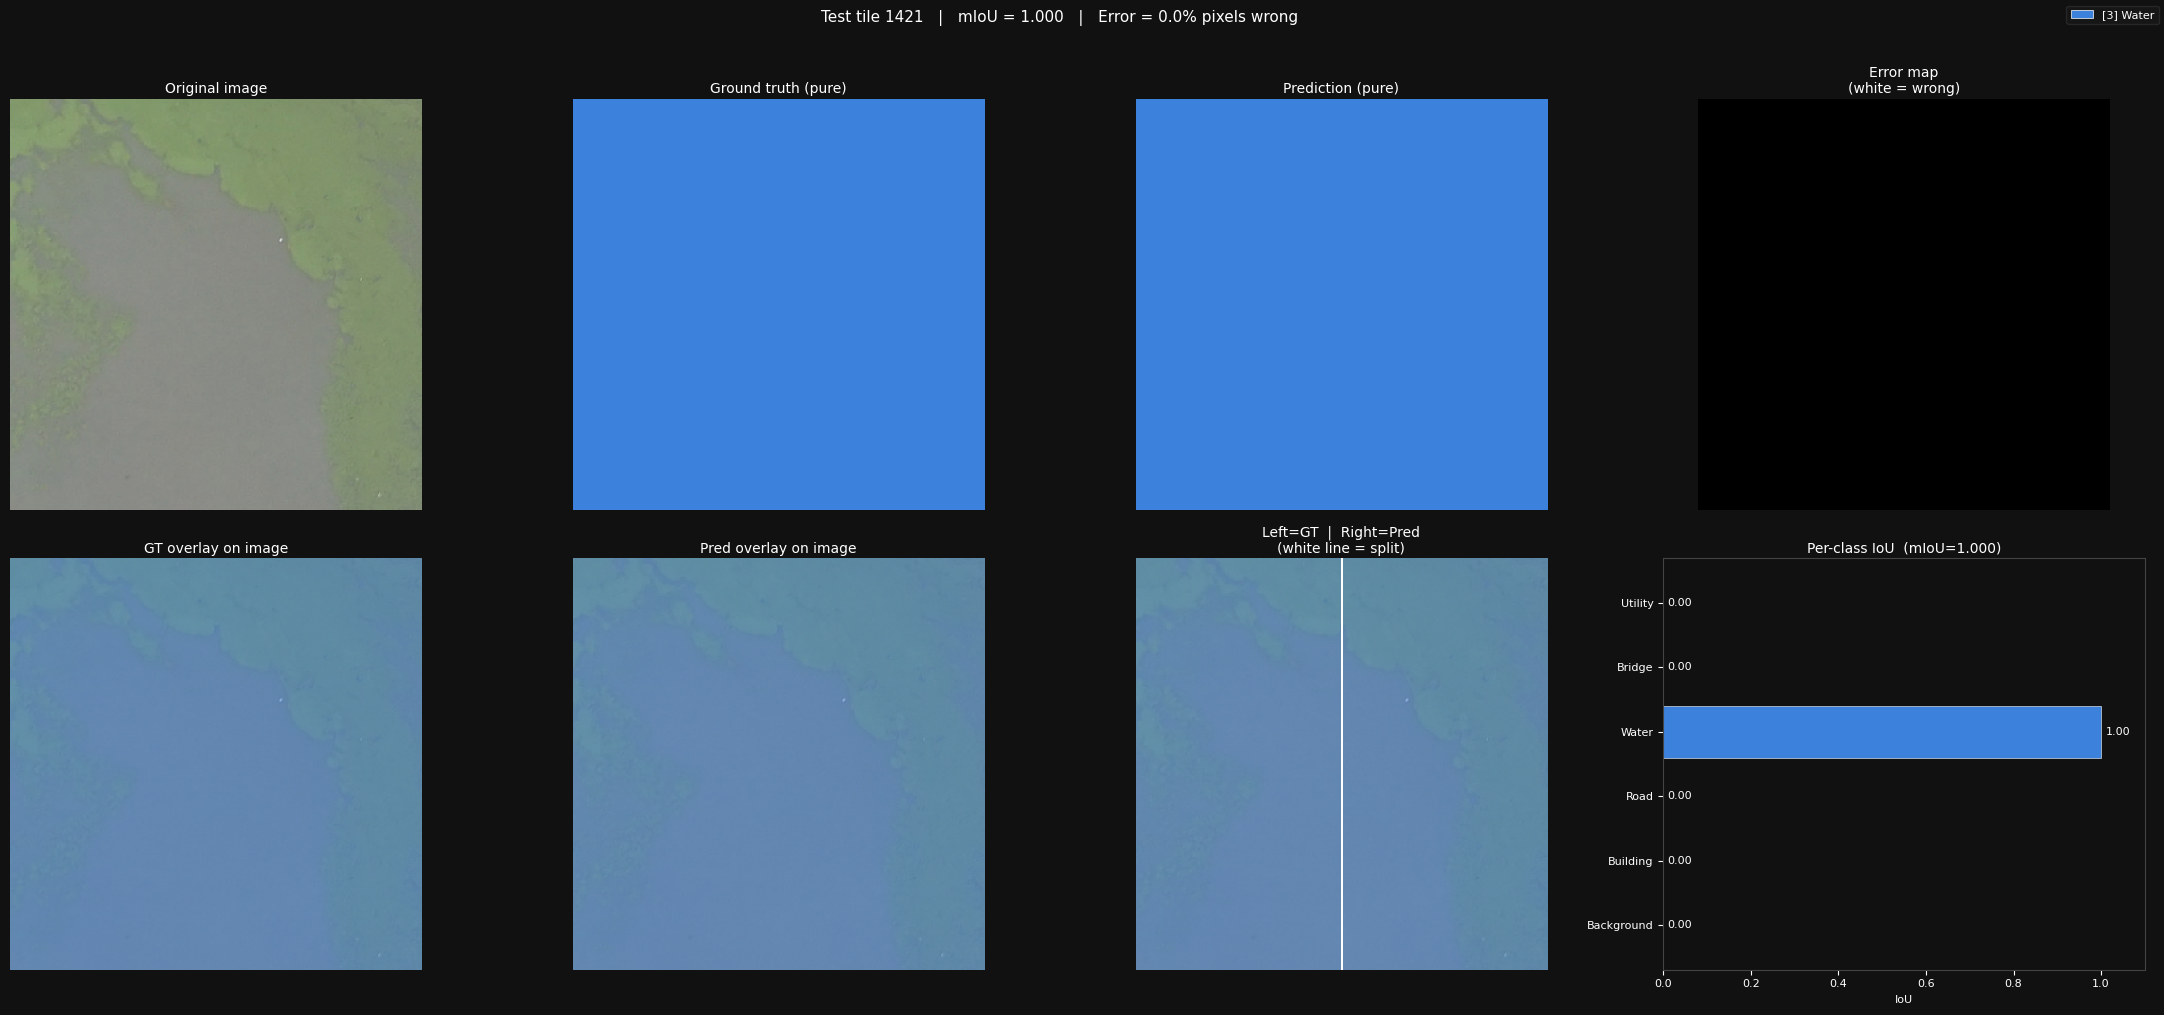


Tile 1421 — mIoU=1.000
  [0] Background  : nan  absent
  [1] Building    : nan  absent
  [2] Road        : nan  absent
  [3] Water       : 1.000  ████████████████████
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



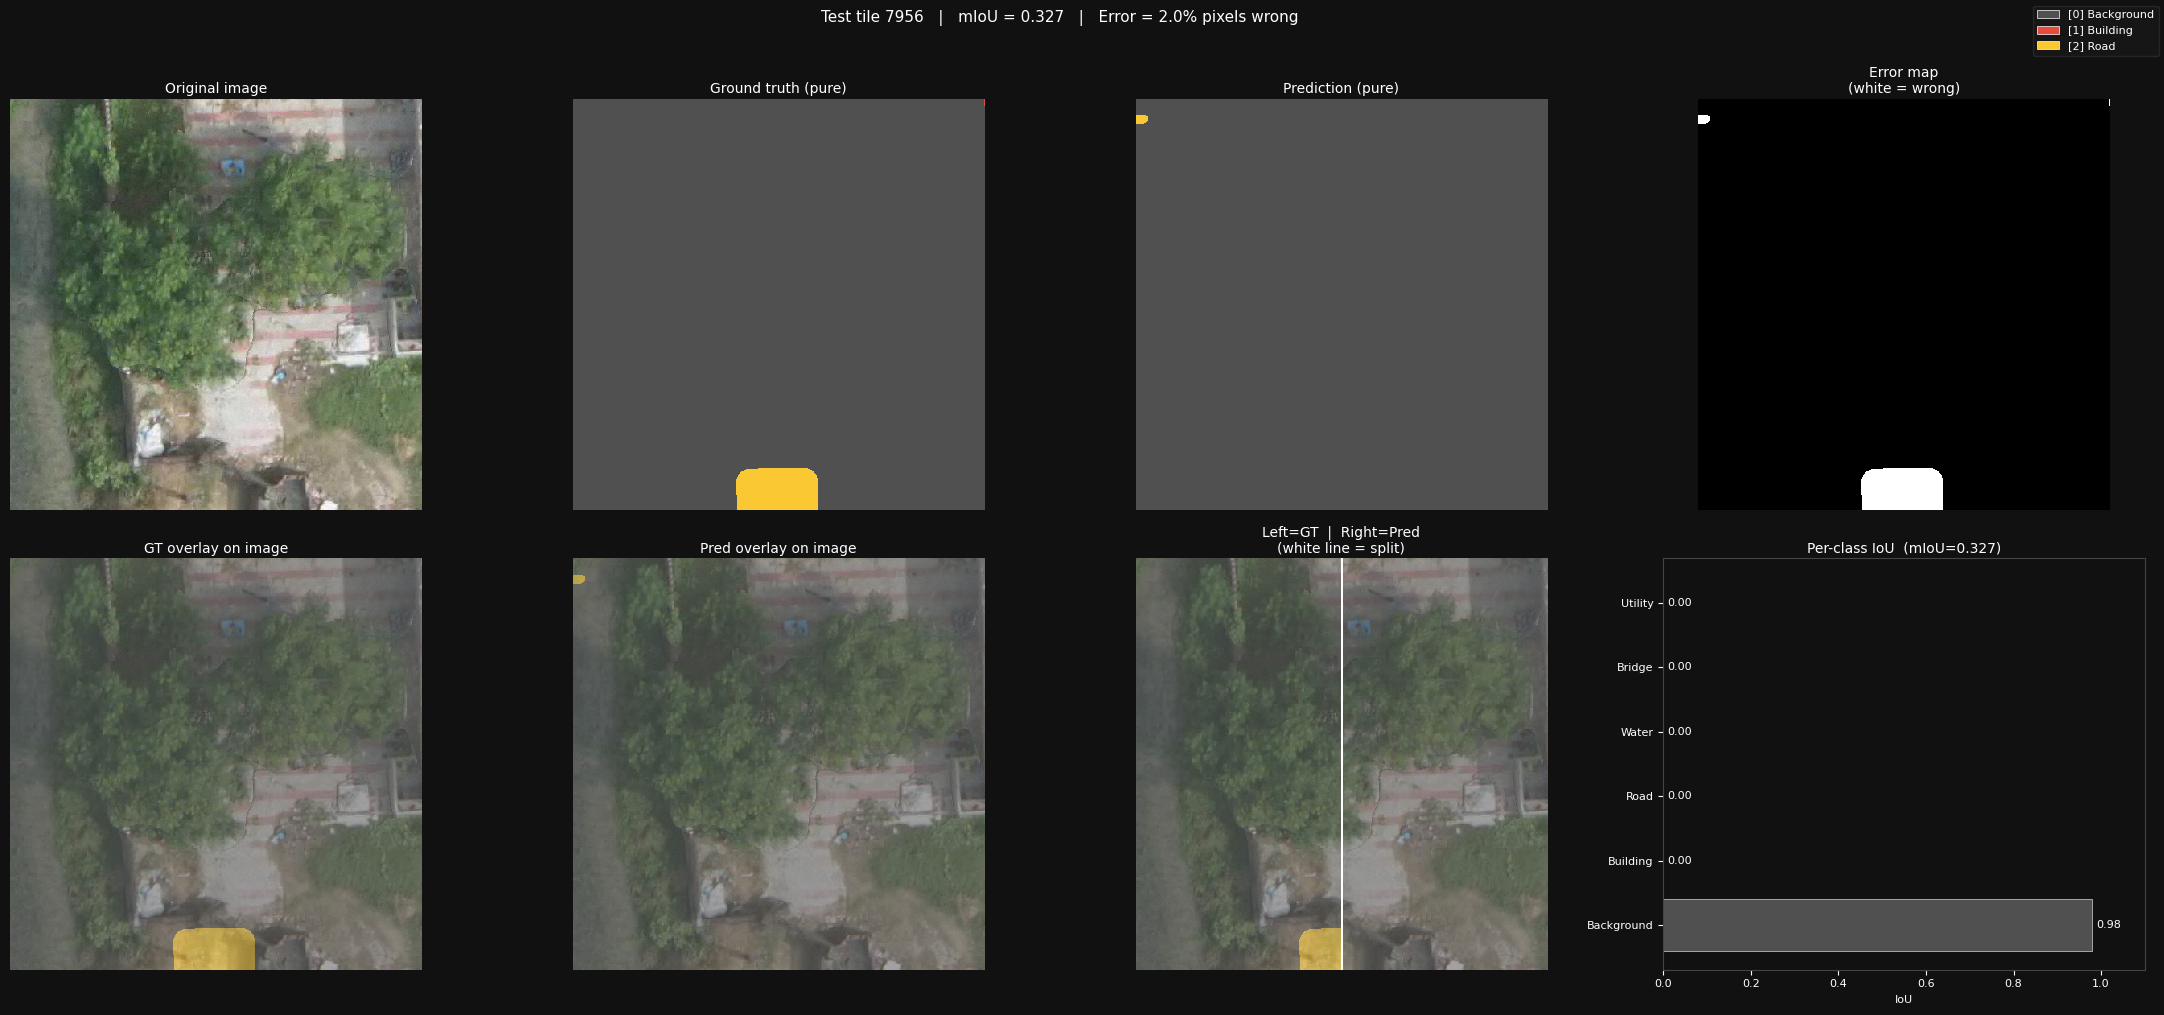


Tile 7956 — mIoU=0.327
  [0] Background  : 0.980  ███████████████████
  [1] Building    : 0.000  
  [2] Road        : 0.000  
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



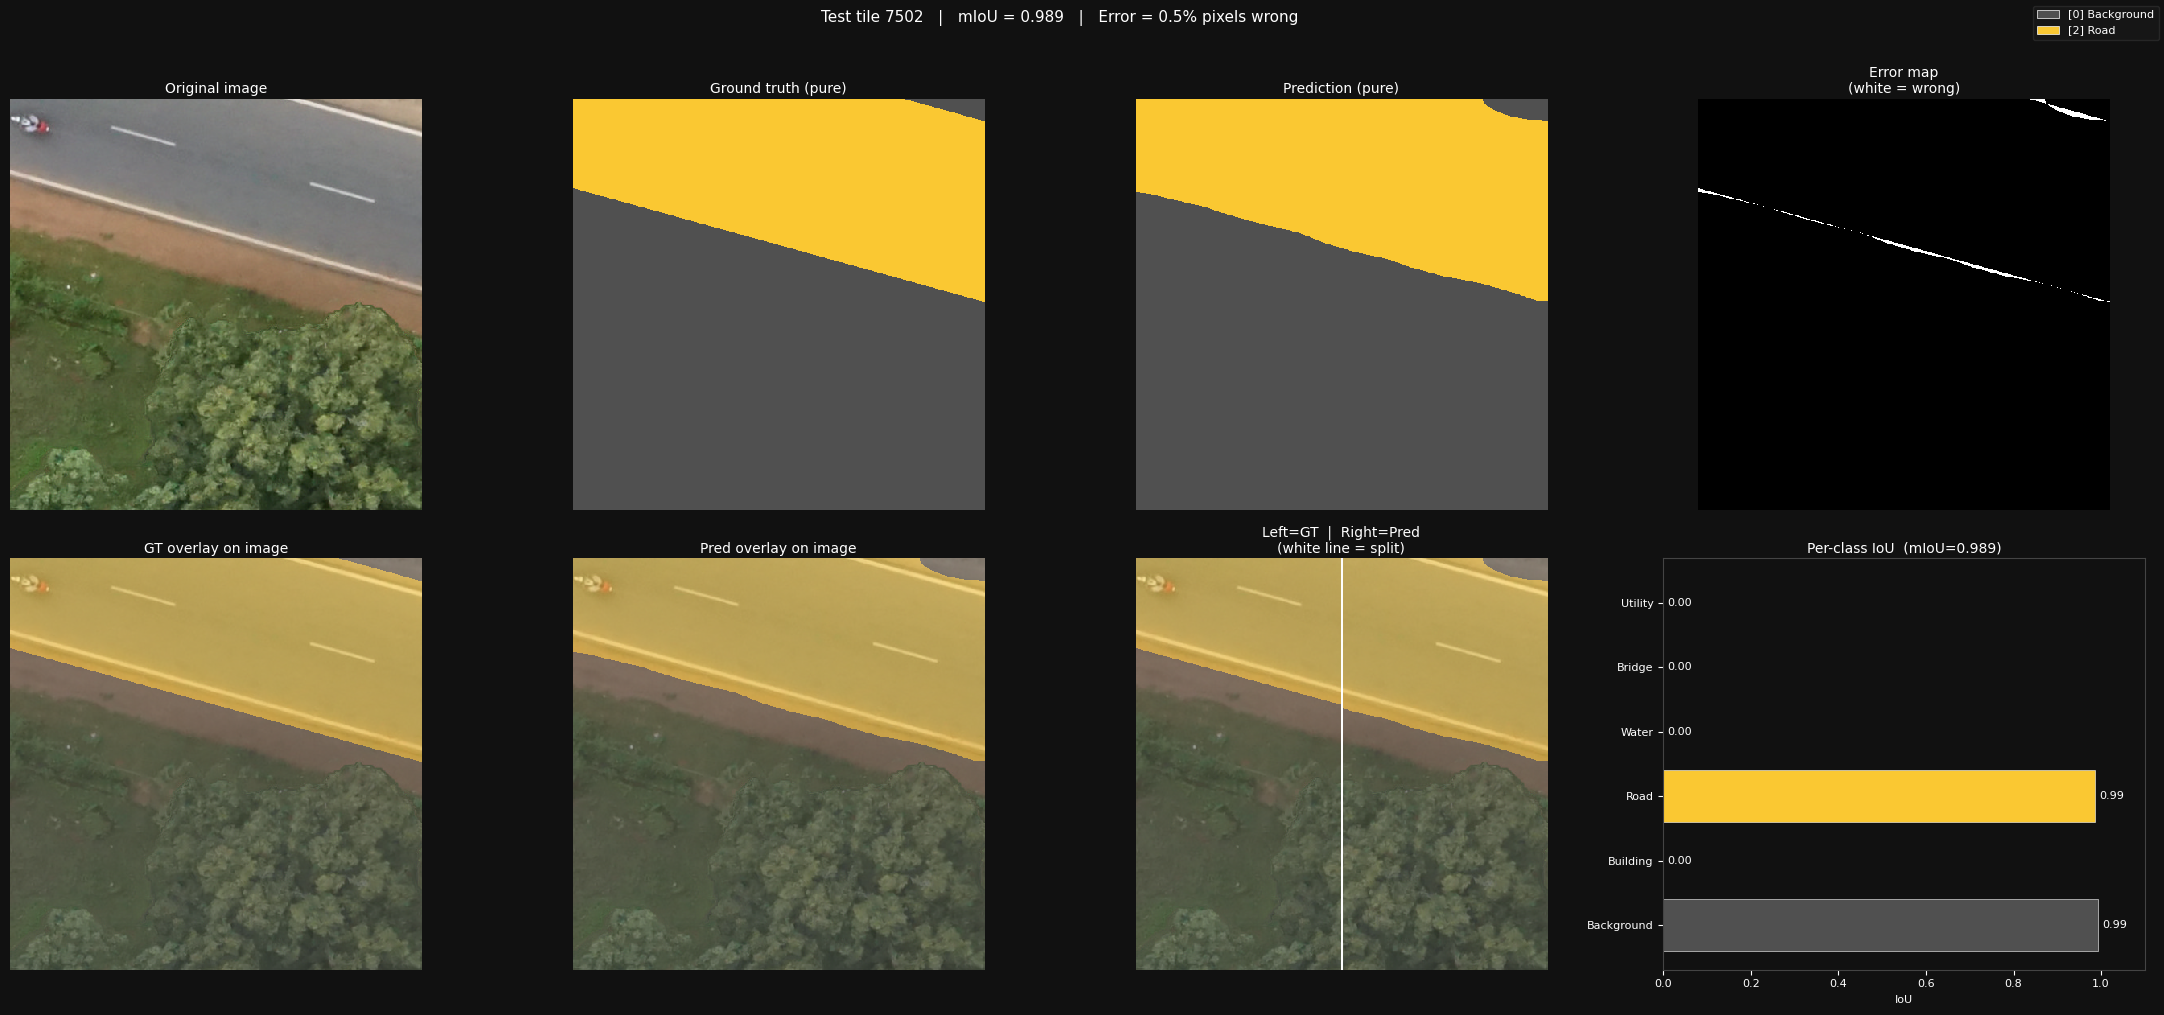


Tile 7502 — mIoU=0.989
  [0] Background  : 0.992  ███████████████████
  [1] Building    : nan  absent
  [2] Road        : 0.986  ███████████████████
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



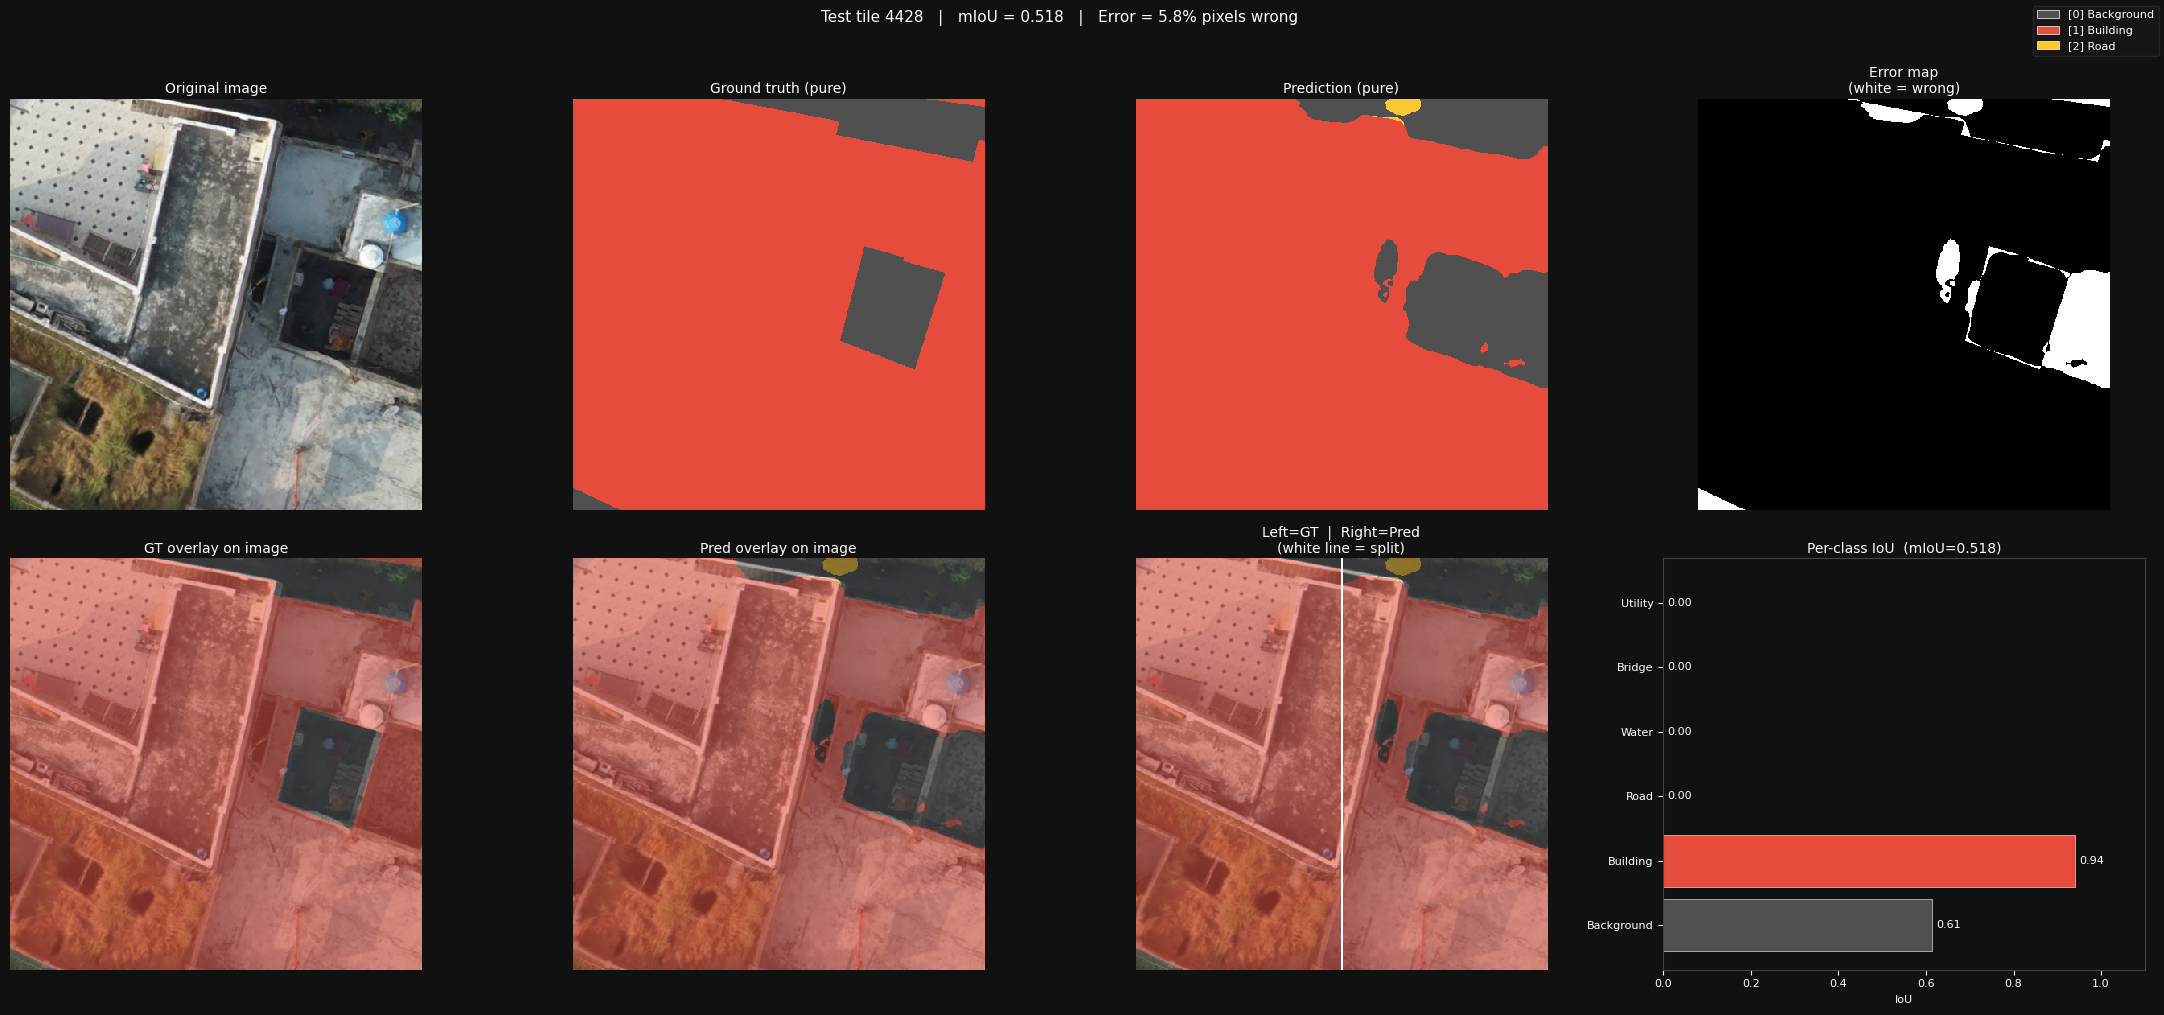


Tile 4428 — mIoU=0.518
  [0] Background  : 0.614  ████████████
  [1] Building    : 0.940  ██████████████████
  [2] Road        : 0.000  
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



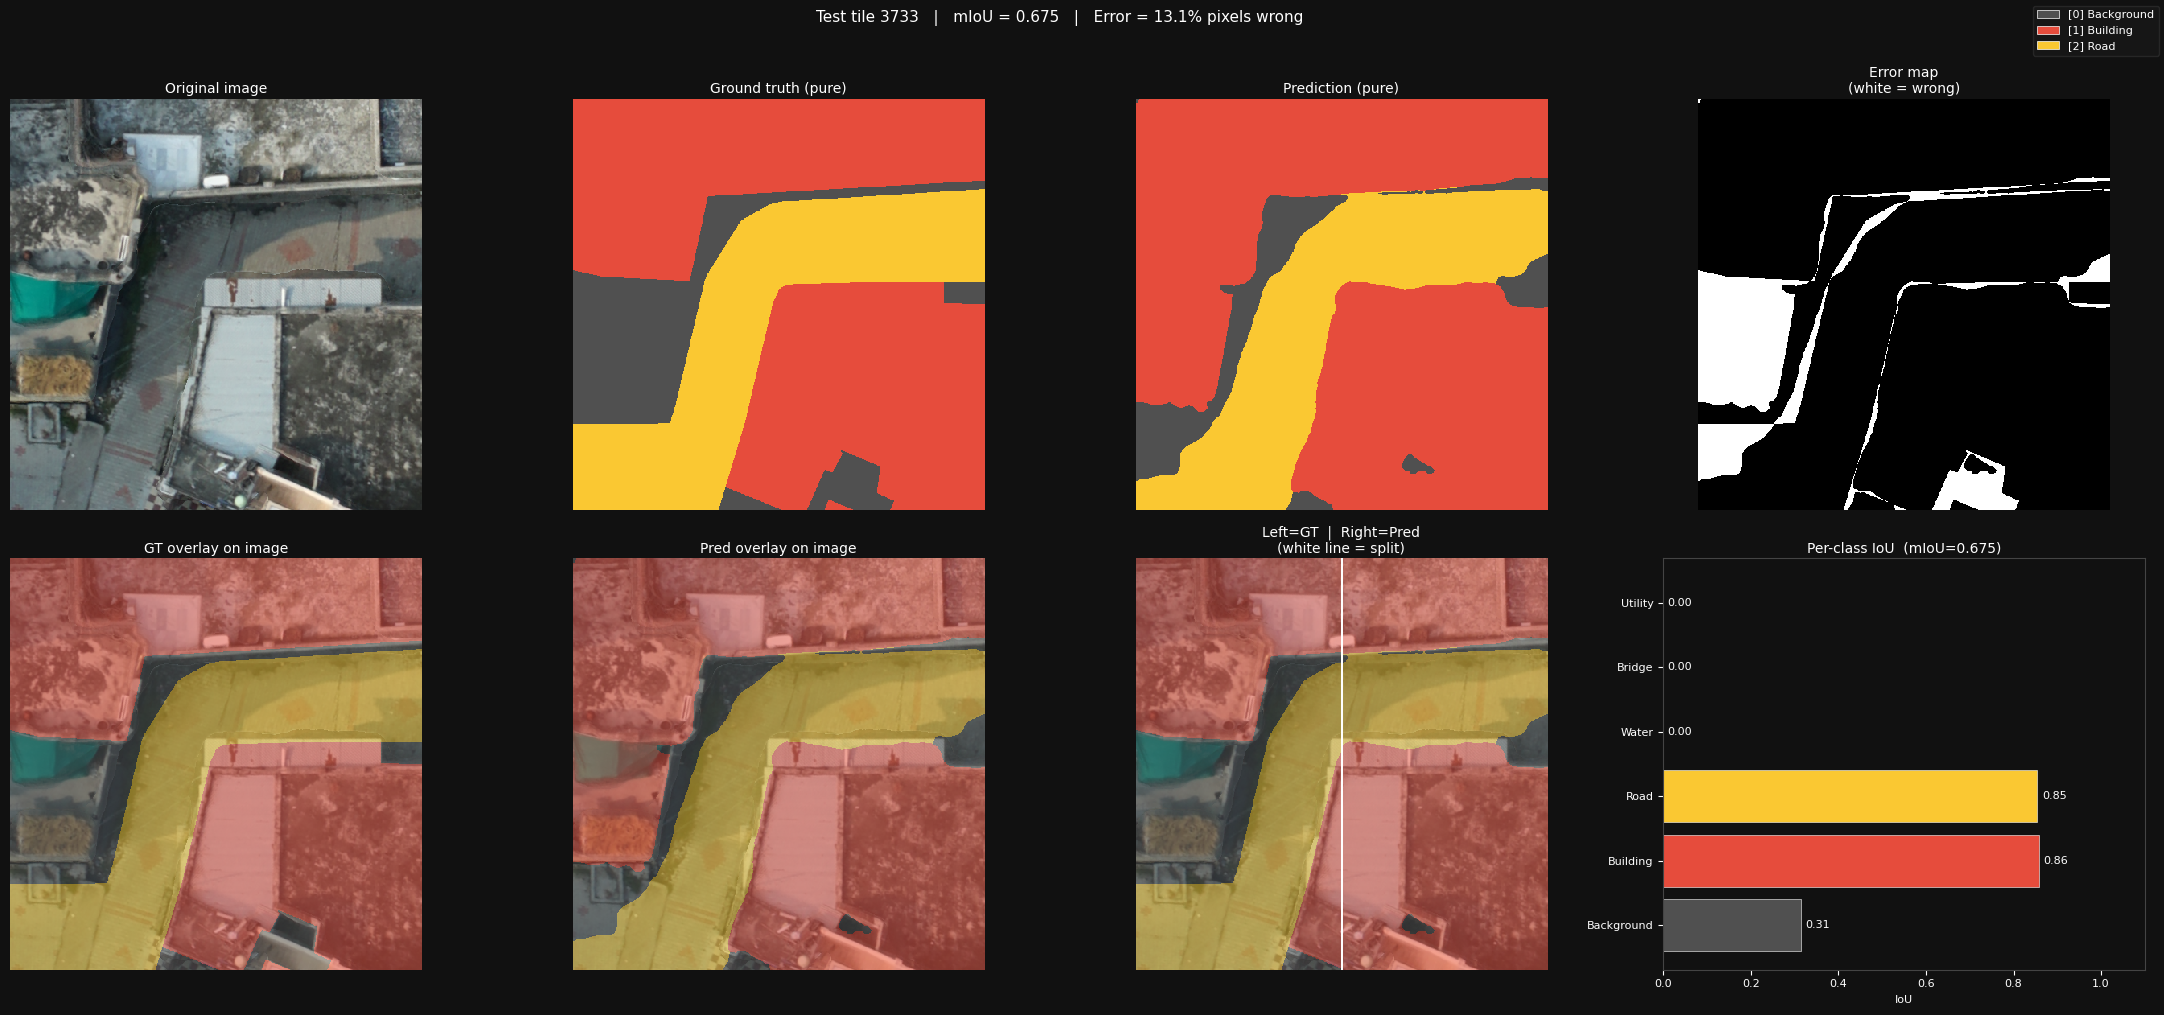


Tile 3733 — mIoU=0.675
  [0] Background  : 0.315  ██████
  [1] Building    : 0.857  █████████████████
  [2] Road        : 0.855  █████████████████
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



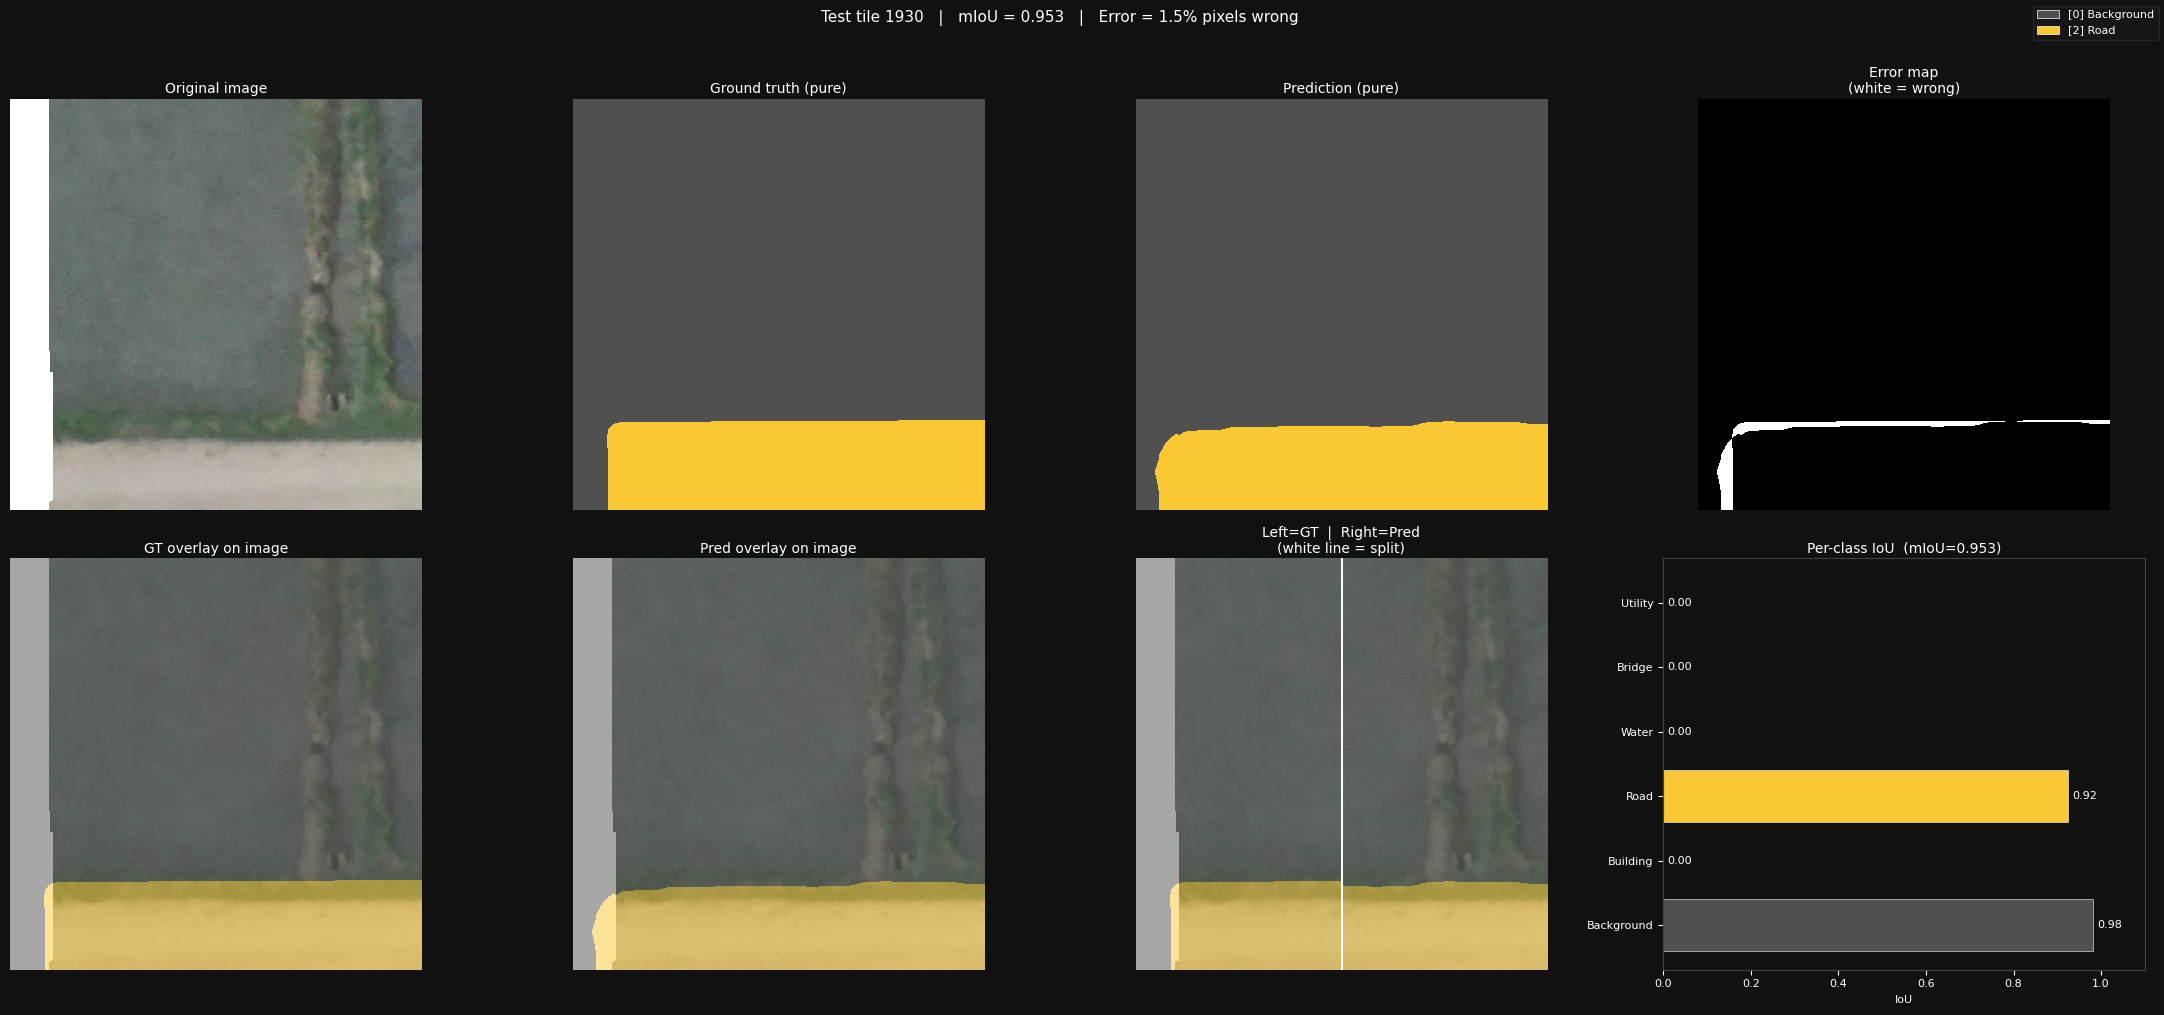


Tile 1930 — mIoU=0.953
  [0] Background  : 0.981  ███████████████████
  [1] Building    : nan  absent
  [2] Road        : 0.925  ██████████████████
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



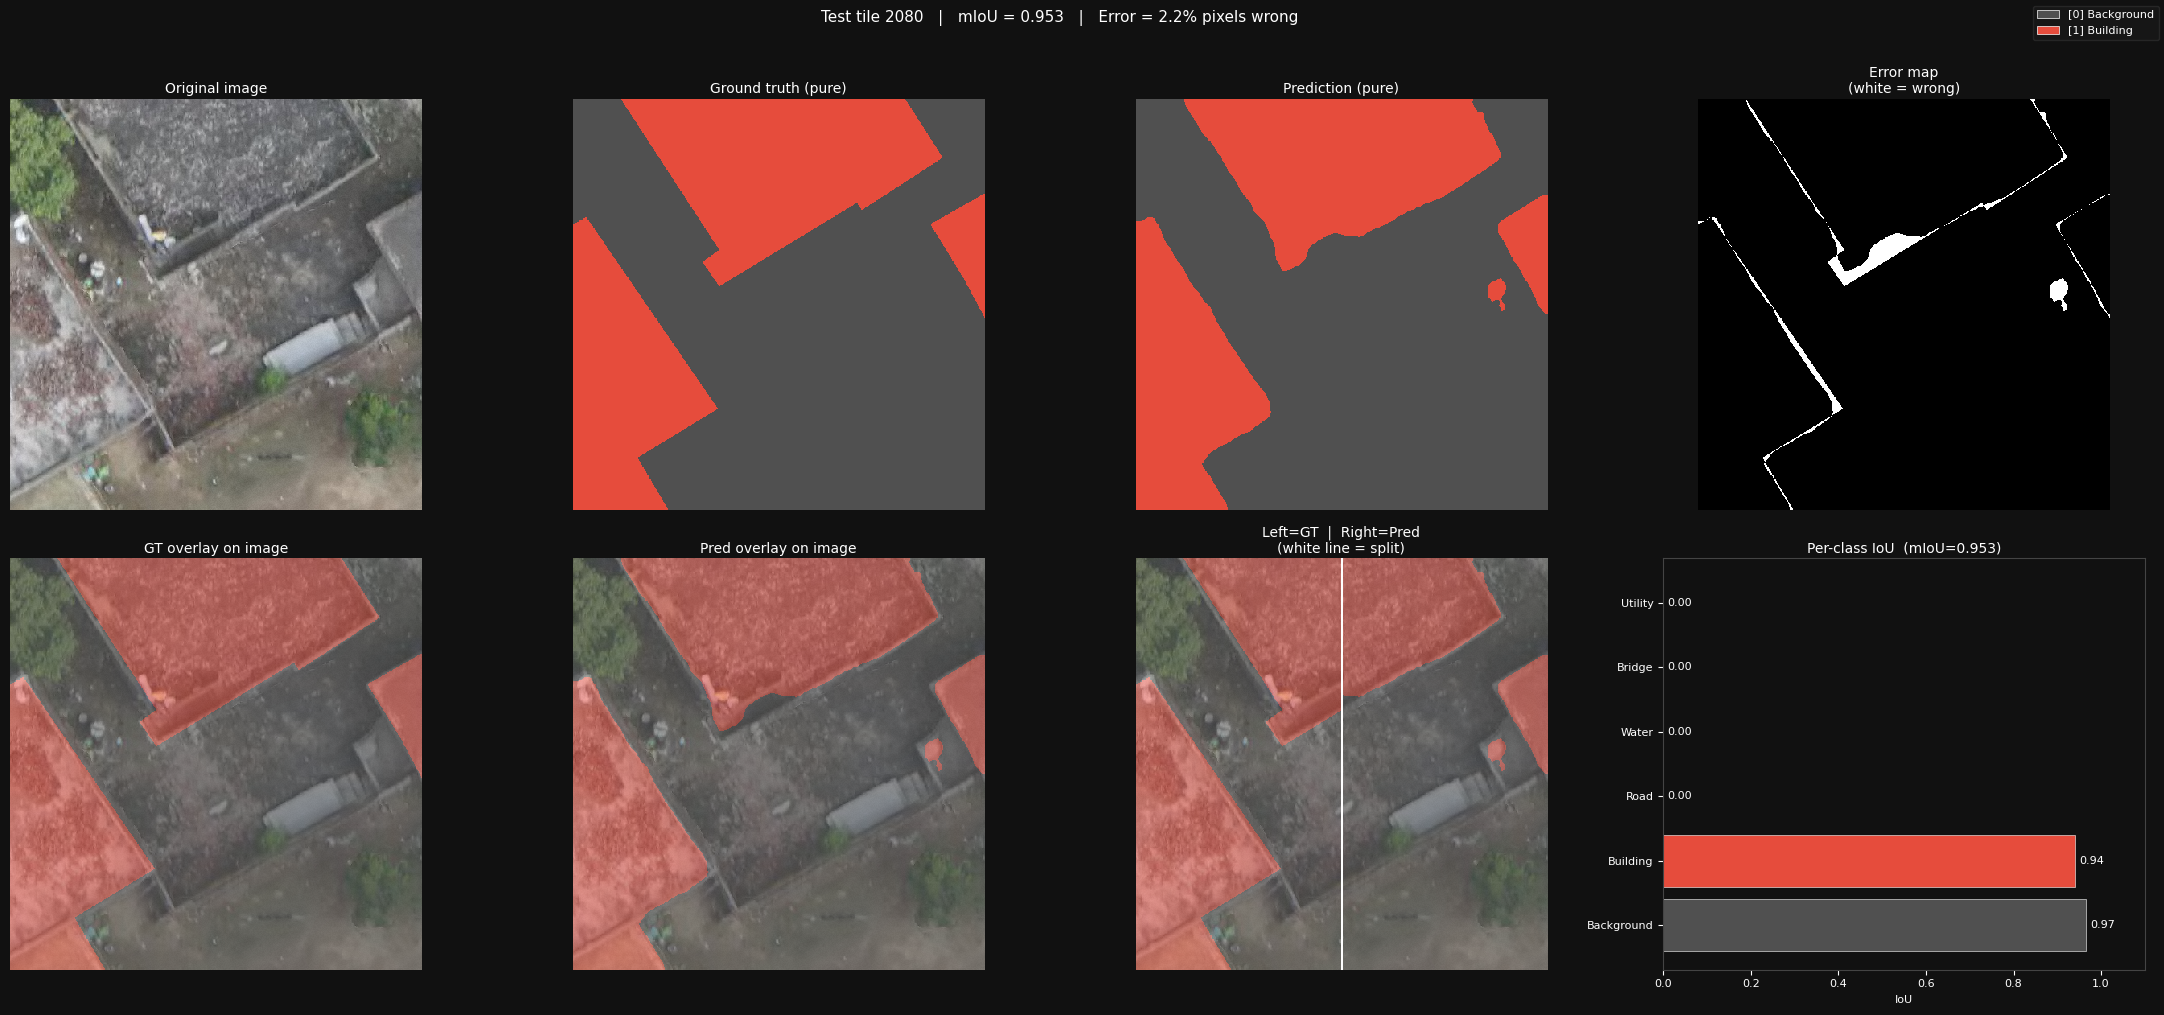


Tile 2080 — mIoU=0.953
  [0] Background  : 0.966  ███████████████████
  [1] Building    : 0.940  ██████████████████
  [2] Road        : nan  absent
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



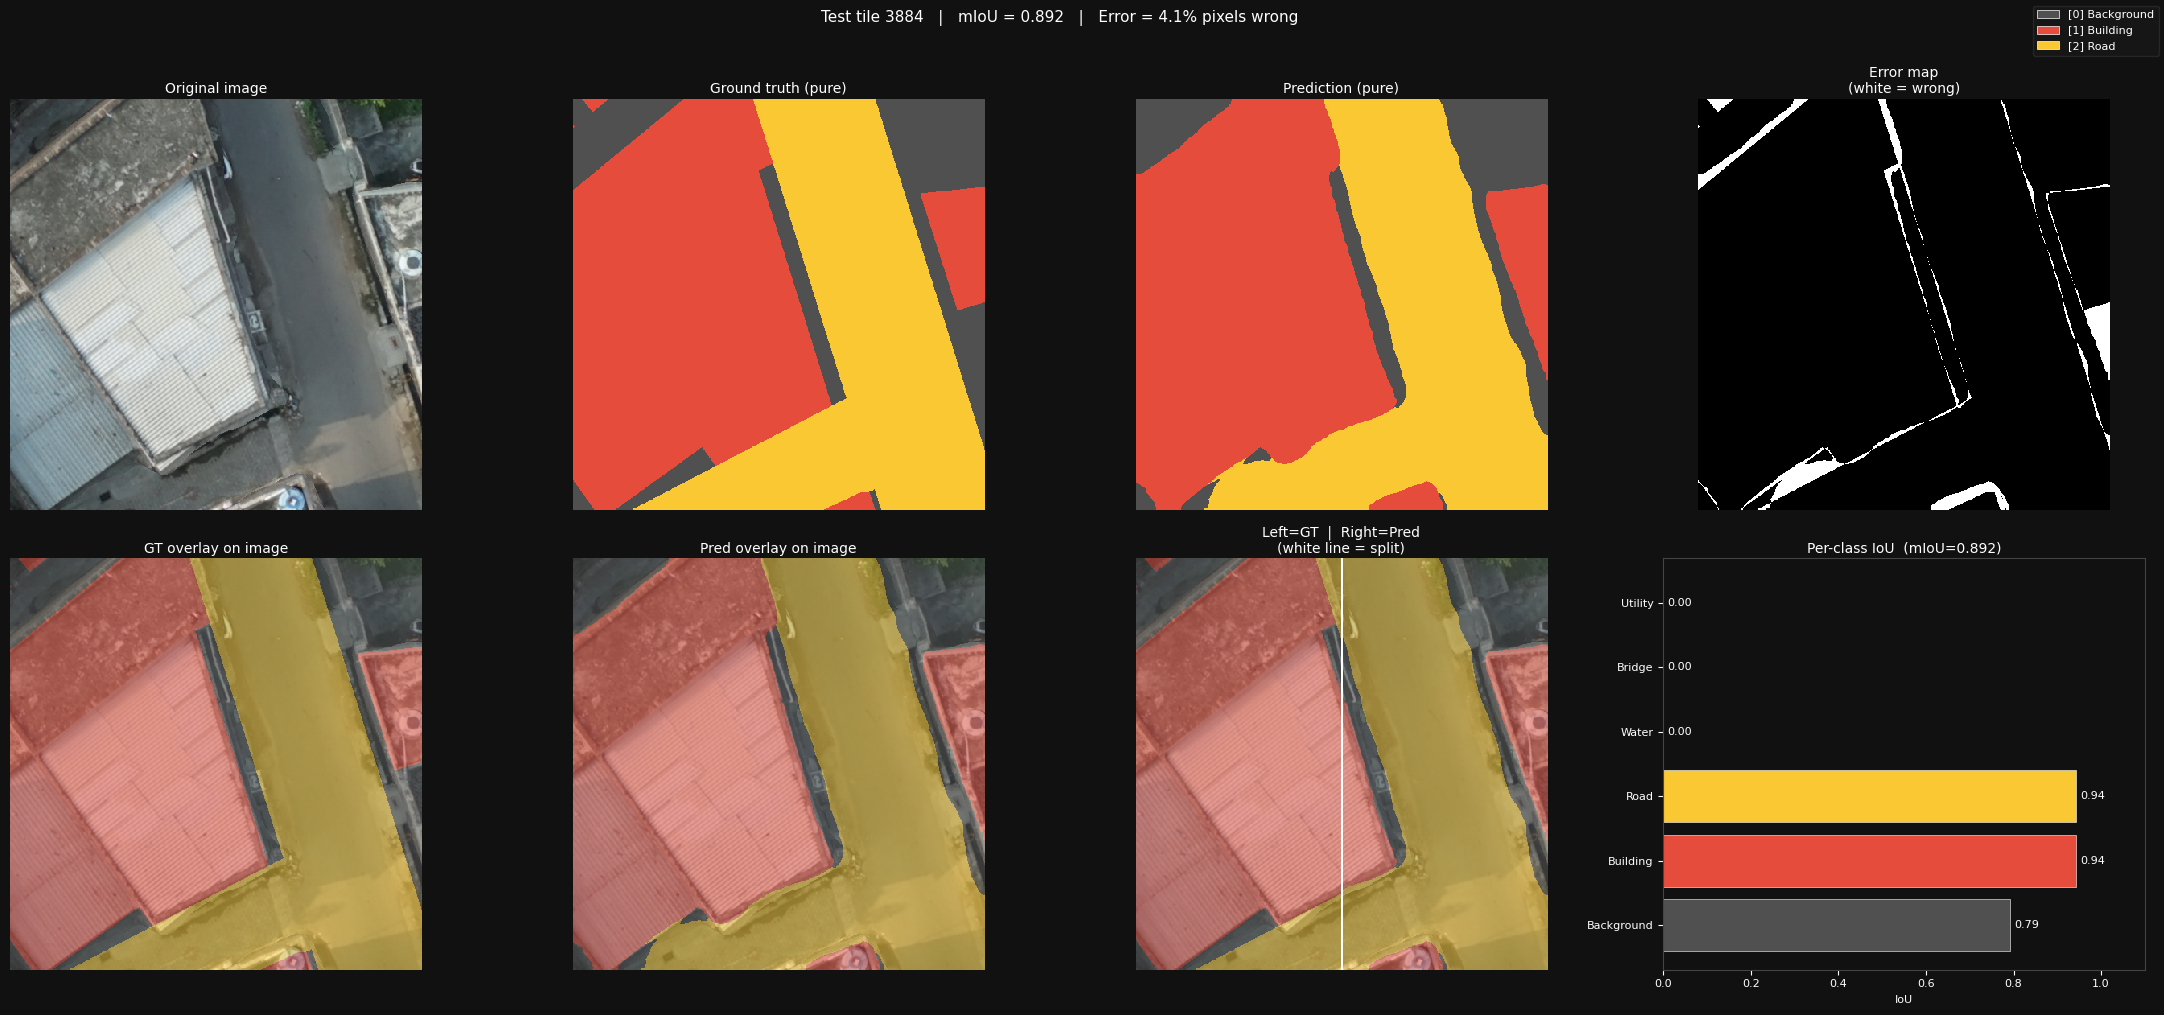


Tile 3884 — mIoU=0.892
  [0] Background  : 0.792  ███████████████
  [1] Building    : 0.942  ██████████████████
  [2] Road        : 0.943  ██████████████████
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



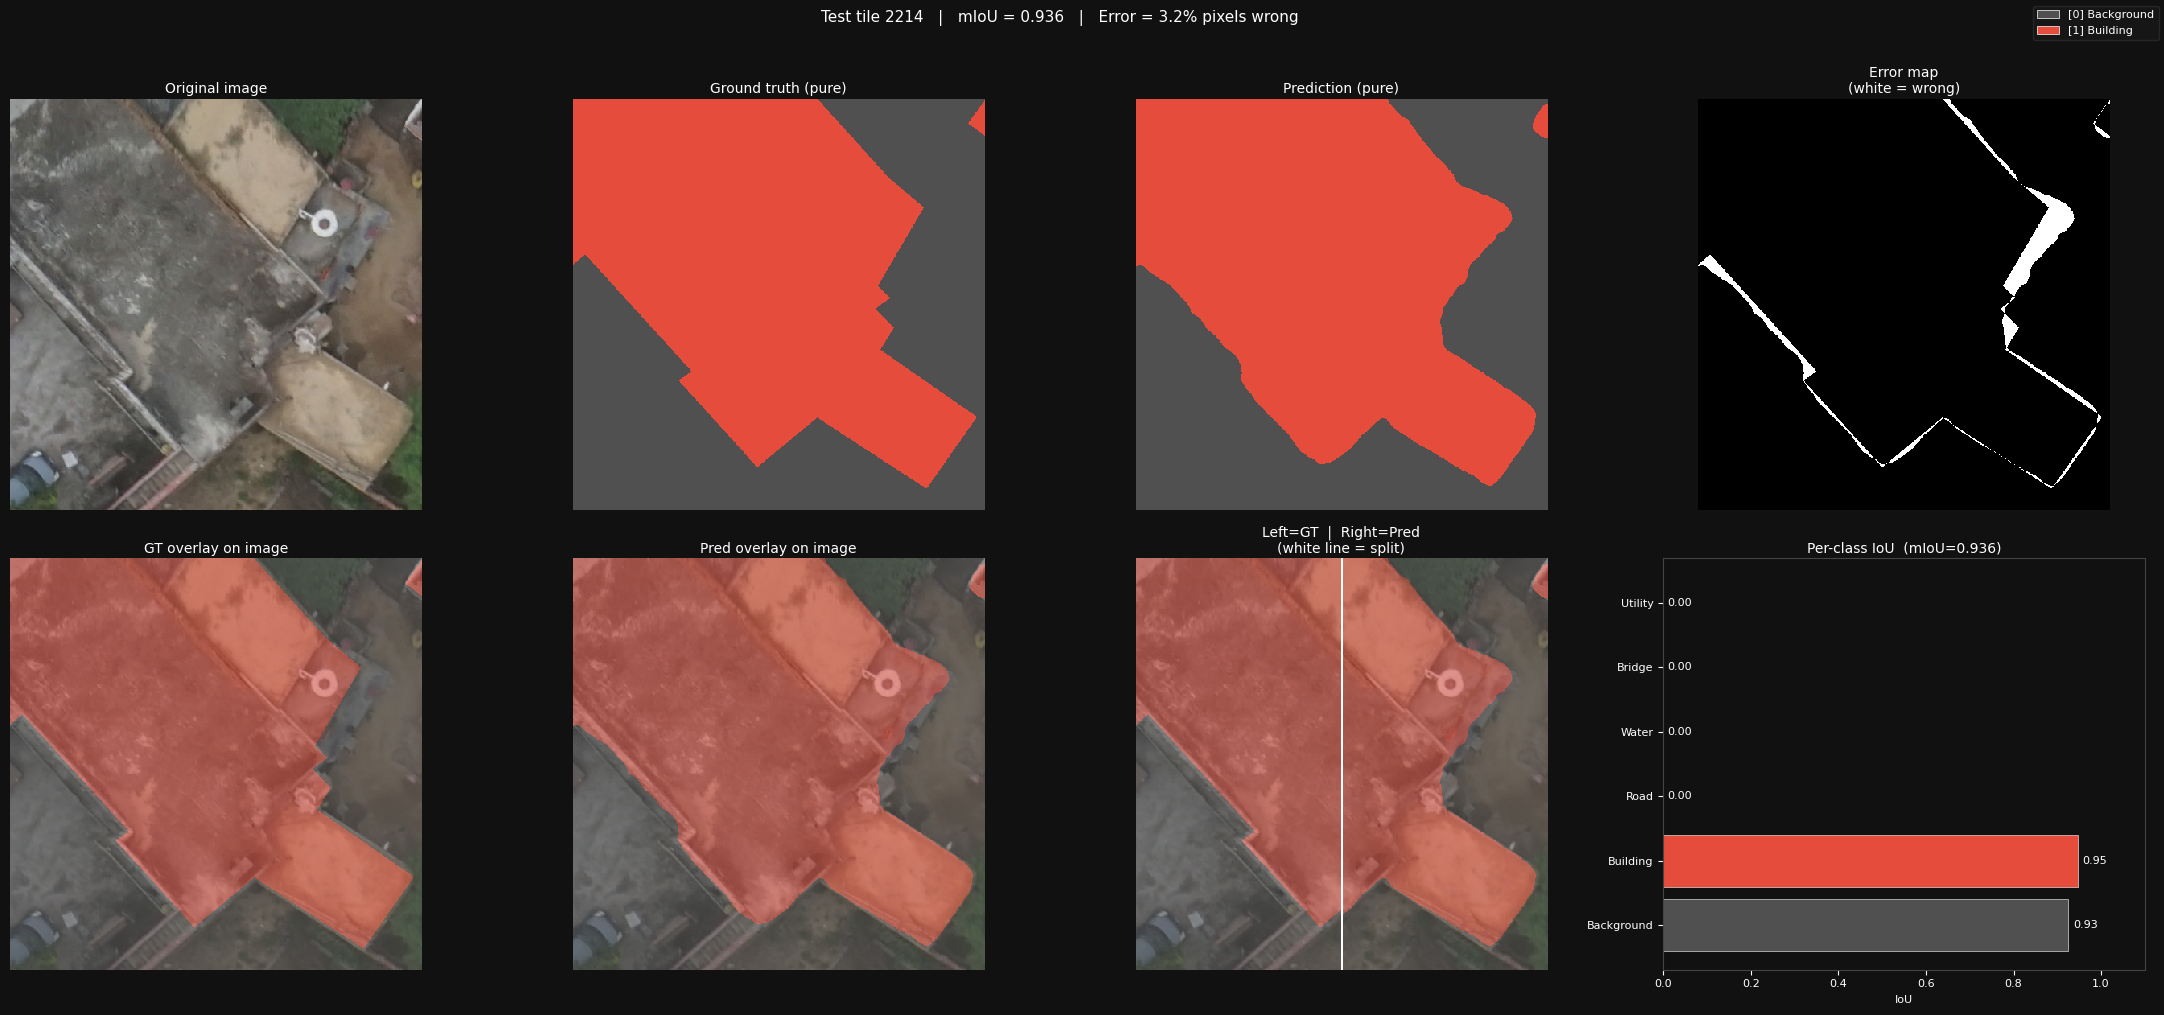


Tile 2214 — mIoU=0.936
  [0] Background  : 0.925  ██████████████████
  [1] Building    : 0.947  ██████████████████
  [2] Road        : nan  absent
  [3] Water       : nan  absent
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent



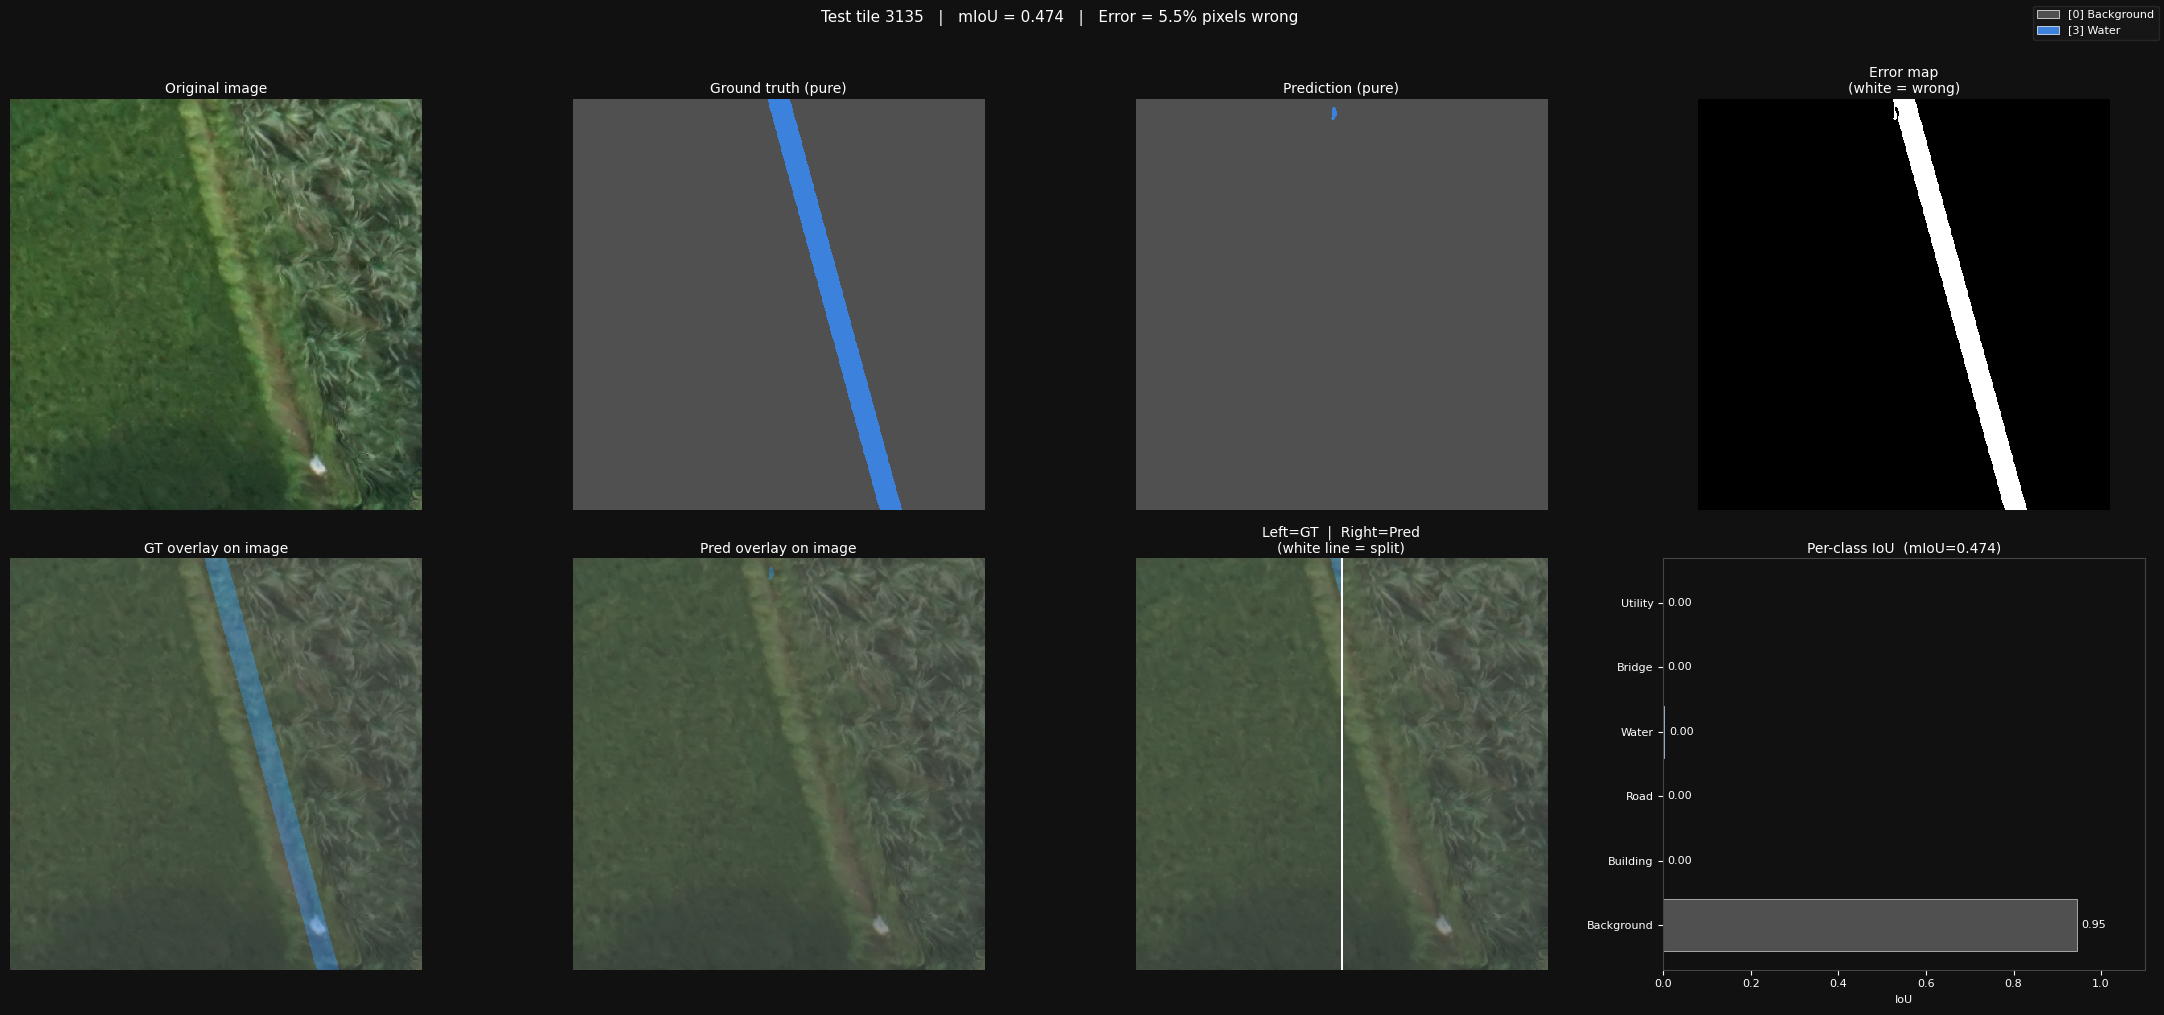


Tile 3135 — mIoU=0.474
  [0] Background  : 0.945  ██████████████████
  [1] Building    : nan  absent
  [2] Road        : nan  absent
  [3] Water       : 0.003  
  [4] Bridge      : nan  absent
  [5] Utility     : nan  absent

OVERALL TEST SET SUMMARY
Mean mIoU across 10 test tiles: 0.7718

Per-class mean IoU:
  [0] Background  : 0.8345  (min=0.315  max=0.992  n=9)
  [1] Building    : 0.7711  (min=0.000  max=0.947  n=6)
  [2] Road        : 0.6180  (min=0.000  max=0.986  n=6)
  [3] Water       : 0.5013  (min=0.003  max=1.000  n=2)
  [4] Bridge      : not present in any test tile
  [5] Utility     : not present in any test tile


In [44]:
# =============================================================
# INFERENCE + OVERLAY VISUALIZATION ON TEST IMAGES
# Run as a single cell in JupyterLab
# Shows: Original | GT | Prediction | Overlay comparison
# =============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os
import random

# ── CONFIG ────────────────────────────────────────────────────
CHECKPOINT_PATH = os.path.join(CFG["checkpoint_dir"], "best_model.pth")
NUM_IMAGES      = 10        # how many test images to visualize
RANDOM_SEED     = None
ALPHA           = 0.5       # overlay transparency

# ── CLASS COLORS (consistent GT and Prediction) ───────────────
SEG_COLORS = {
    0: (80,  80,  80),    # Background — grey
    1: (230, 76,  60),    # Building   — red
    2: (250, 200, 50),    # Road       — yellow
    3: (60,  130, 220),   # Water      — blue
    4: (255, 140, 0),     # Bridge     — orange
    5: (80,  200, 120),   # Utility    — green
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── HELPERS ───────────────────────────────────────────────────
def apply_color_map(label_map, color_dict):
    """HxW int array → HxW×3 RGB."""
    h, w  = label_map.shape
    rgb   = np.zeros((h, w, 3), dtype=np.uint8)
    for cls_id, color in color_dict.items():
        rgb[label_map == cls_id] = color
    return rgb


def blend_overlay(image_rgb, color_mask, alpha=0.5):
    """Blend colour mask onto image."""
    img = image_rgb.astype(np.float32)
    msk = color_mask.astype(np.float32)
    out = img * (1 - alpha) + msk * alpha
    return np.clip(out, 0, 255).astype(np.uint8)


def compute_iou_per_class(pred, gt, num_classes):
    ious = {}
    for c in range(num_classes):
        inter = ((pred == c) & (gt == c)).sum()
        union = ((pred == c) | (gt == c)).sum()
        ious[c] = inter / union if union > 0 else float('nan')
    return ious


def make_legend(color_dict, label_dict, present_classes):
    handles = []
    for c in present_classes:
        col = [x/255 for x in color_dict[c]]
        handles.append(mpatches.Patch(
            facecolor=col, edgecolor='white',
            linewidth=0.5,
            label=f"[{c}] {label_dict[c]}"
        ))
    return handles


# ── LOAD MODEL ────────────────────────────────────────────────
print(f"Loading checkpoint: {CHECKPOINT_PATH}")
assert os.path.exists(CHECKPOINT_PATH), f"Checkpoint not found: {CHECKPOINT_PATH}"
ckpt = torch.load(CHECKPOINT_PATH, map_location=CFG["device"], weights_only=False)

model.load_state_dict(ckpt["model"])
model.eval()
print(f"Model loaded — best mIoU was: {ckpt.get('best_score', 'N/A')}")

# ── TRANSFORM (val transform — no augmentation) ───────────────
infer_transform = A.Compose([
    A.Resize(CFG["image_size"], CFG["image_size"]),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# ── SELECT TEST IMAGES ────────────────────────────────────────
random.seed(RANDOM_SEED)
sample_ids = random.sample(test_ids, min(NUM_IMAGES, len(test_ids)))
print(f"Evaluating {len(sample_ids)} test images...")

# ── INFERENCE LOOP ────────────────────────────────────────────
all_results = []

for fid in sample_ids:
    # Load
    img_path  = os.path.join(IMAGE_DIR, f"{fid}.png")
    mask_path = os.path.join(MASK_DIR,  f"{fid}.png")

    image_raw = np.array(Image.open(img_path).convert("RGB"))
    mask_raw  = np.clip(
        np.array(Image.open(mask_path)), 0, CFG["num_classes"] - 1
    ).astype(np.int64)

    h_orig, w_orig = image_raw.shape[:2]

    # Transform
    img_t = infer_transform(image=image_raw)["image"] \
               .unsqueeze(0).to(CFG["device"])

    # Inference
    with torch.no_grad(), torch.amp.autocast(
            "cuda", dtype=torch.bfloat16, enabled=CFG["use_amp"]):
        outputs   = model(pixel_values=img_t)
        logits_up = F.interpolate(
            outputs.logits,
            size=(h_orig, w_orig),
            mode="bilinear",
            align_corners=False,
        )

    probs    = torch.softmax(logits_up, dim=1)[0].cpu()
    pred_np  = probs.argmax(dim=0).numpy().astype(np.int64)

    # IoU
    iou_dict = compute_iou_per_class(pred_np, mask_raw, CFG["num_classes"])
    miou     = np.nanmean(list(iou_dict.values()))

    all_results.append({
        "fid"      : fid,
        "image"    : image_raw,
        "gt"       : mask_raw,
        "pred"     : pred_np,
        "iou"      : iou_dict,
        "miou"     : miou,
        "probs"    : probs.numpy(),
    })

print(f"Inference complete on {len(all_results)} images")

# ── VISUALIZATION ─────────────────────────────────────────────
BG = "#111111"

for idx, res in enumerate(all_results):
    fid       = res["fid"]
    image     = res["image"]
    gt_np     = res["gt"]
    pred_np   = res["pred"]
    iou_dict  = res["iou"]
    miou      = res["miou"]

    # Colour maps
    gt_rgb   = apply_color_map(gt_np,   SEG_COLORS)
    pred_rgb = apply_color_map(pred_np, SEG_COLORS)

    # Overlays
    gt_overlay   = blend_overlay(image, gt_rgb,   alpha=ALPHA)
    pred_overlay = blend_overlay(image, pred_rgb, alpha=ALPHA)

    # Error map — white where wrong
    error_map = (pred_np != gt_np).astype(np.uint8) * 255

    # Figure: 2 rows × 4 cols
    fig, axes = plt.subplots(2, 4, figsize=(22, 10),
                              facecolor=BG)
    fig.patch.set_facecolor(BG)

    def show(ax, img, title, cmap=None):
        ax.set_facecolor(BG)
        ax.imshow(img, cmap=cmap, interpolation='nearest')
        ax.set_title(title, color='white', fontsize=10, pad=4)
        ax.axis('off')

    # Row 0
    show(axes[0,0], image,        "Original image")
    show(axes[0,1], gt_rgb,       "Ground truth (pure)")
    show(axes[0,2], pred_rgb,     "Prediction (pure)")
    show(axes[0,3], error_map,    "Error map\n(white = wrong)",
         cmap='gray')

    # Row 1
    show(axes[1,0], gt_overlay,   "GT overlay on image")
    show(axes[1,1], pred_overlay, "Pred overlay on image")

    # Side by side diff
    # Left half = GT, Right half = Pred
    h, w = image.shape[:2]
    split = np.concatenate([
        gt_overlay[:, :w//2],
        pred_overlay[:, w//2:]
    ], axis=1)
    # Draw dividing line
    split[:, w//2-1:w//2+1] = [255, 255, 255]
    show(axes[1,2], split,
         "Left=GT  |  Right=Pred\n(white line = split)")

    # IoU bar chart
    axes[1,3].set_facecolor(BG)
    axes[1,3].axis('on')
    classes = list(range(CFG["num_classes"]))
    vals    = [iou_dict[c] if not np.isnan(iou_dict[c]) else 0.0
               for c in classes]
    colors  = [[x/255 for x in SEG_COLORS[c]] for c in classes]
    labels  = [ID2LABEL[c] for c in classes]
    bars    = axes[1,3].barh(labels, vals, color=colors,
                              edgecolor='white', linewidth=0.4)
    axes[1,3].set_xlim(0, 1.1)
    axes[1,3].set_xlabel("IoU", color='white', fontsize=8)
    axes[1,3].set_title(f"Per-class IoU  (mIoU={miou:.3f})",
                         color='white', fontsize=10, pad=4)
    axes[1,3].tick_params(colors='white', labelsize=8)
    for spine in axes[1,3].spines.values():
        spine.set_edgecolor('#444')
    for bar, v in zip(bars, vals):
        axes[1,3].text(
            v + 0.01, bar.get_y() + bar.get_height()/2,
            f"{v:.2f}", va='center', color='white', fontsize=8
        )

    # Legend + title
    all_classes  = sorted(set(np.unique(gt_np)) |
                          set(np.unique(pred_np)))
    present      = [c for c in all_classes if c in SEG_COLORS]
    leg_handles  = make_legend(SEG_COLORS, ID2LABEL, present)

    fig.legend(
        handles=leg_handles,
        loc='upper right',
        fontsize=8,
        frameon=True,
        framealpha=0.3,
        facecolor='#222',
        edgecolor='#555',
        labelcolor='white',
    )

    # Error %
    err_pct = 100 * error_map.sum() / (255 * error_map.size)

    fig.suptitle(
        f"Test tile {fid}   |   mIoU = {miou:.3f}   "
        f"|   Error = {err_pct:.1f}% pixels wrong",
        color='white', fontsize=11, y=1.01
    )

    plt.tight_layout()
    plt.show()
    print(f"\nTile {fid} — mIoU={miou:.3f}")
    for c in range(CFG["num_classes"]):
        v   = iou_dict[c]
        bar = "█" * int(v*20) if not np.isnan(v) else "absent"
        print(f"  [{c}] {ID2LABEL[c]:12s}: "
              f"{v:.3f}  {bar}")
    print()

# ── OVERALL TEST SET SUMMARY ──────────────────────────────────
print("=" * 50)
print("OVERALL TEST SET SUMMARY")
print("=" * 50)

mean_miou  = np.mean([r["miou"] for r in all_results])
class_ious = {c: [] for c in range(CFG["num_classes"])}

for r in all_results:
    for c in range(CFG["num_classes"]):
        v = r["iou"][c]
        if not np.isnan(v):
            class_ious[c].append(v)

print(f"Mean mIoU across {len(all_results)} test tiles: {mean_miou:.4f}\n")
print("Per-class mean IoU:")
for c in range(CFG["num_classes"]):
    vals = class_ious[c]
    if vals:
        print(f"  [{c}] {ID2LABEL[c]:12s}: "
              f"{np.mean(vals):.4f}  "
              f"(min={np.min(vals):.3f}  "
              f"max={np.max(vals):.3f}  "
              f"n={len(vals)})")
    else:
        print(f"  [{c}] {ID2LABEL[c]:12s}: not present in any test tile")

In [32]:
!pip install matplotlib -q

In [45]:
# =============================================================
# INFERENCE → GPKG PIPELINE
# Runs segmentation on GeoTIFF tiles → outputs GeoPackage
# Compatible with JupyterLab local setup
# =============================================================

# =========================
# INSTALL (run once)
# =========================
import subprocess
subprocess.run(["pip", "install", "-q", "rasterio", "geopandas",
                "shapely", "tqdm"], check=False)

# =========================
# IMPORTS
# =========================
import os
import numpy as np
import torch
import torch.nn.functional as F
import rasterio
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape
from shapely.ops import unary_union
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation
import warnings
warnings.filterwarnings("ignore")

# =========================
# PATHS — CHANGE THESE
# =========================
TILES_DIR   = "/home/user1/jupyterlab/Village2"          # folder with .tif tiles
SEG_CKPT    = "/home/user1/jupyterlab/segformer_ckpts1/best_model.pth"
OUTPUT_GPKG = "/home/user1/jupyterlab/village_output1.gpkg"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

# =========================
# CONFIG
# =========================
NUM_SEG_CLASSES  = 6
NUM_ROOF_CLASSES = 5
BACKBONE         = "nvidia/mit-b3"    # must match training backbone
IMAGE_SIZE       = 512                # must match CFG["image_size"]

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Class mapping
ID2LABEL = {
    0: "Background",
    1: "Building",
    2: "Road",
    3: "Water",
    4: "Bridge",
    5: "Utility",
}

# =========================
# LOAD MODEL
# =========================
print(f"\nLoading segmentation model from:\n  {SEG_CKPT}")
assert os.path.exists(SEG_CKPT), f"Checkpoint not found: {SEG_CKPT}"

model = SegformerForSemanticSegmentation.from_pretrained(
    BACKBONE,
    num_labels=NUM_SEG_CLASSES,
    ignore_mismatched_sizes=True,
    drop_path_rate=0.1,
)

ckpt = torch.load(SEG_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model"])
model = model.to(DEVICE)
model.eval()

print(f"Model loaded — best mIoU was: {ckpt.get('best_score', 'N/A'):.4f}")

# =========================
# TRANSFORM
# =========================
infer_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# =========================
# INFERENCE FUNCTION
# =========================
def predict_tile(image_rgb):
    """
    image_rgb: HxWx3 uint8 numpy array
    Returns: HxW int64 segmentation mask at original resolution
    """
    h, w = image_rgb.shape[:2]

    # Skip near-white nodata tiles (other village patches in TIF)
    mean_val = image_rgb.mean()
    if mean_val > 248 or mean_val < 5:
        return None   # nodata tile — skip

    # Check if >50% white pixels — nodata area
    white_mask  = ((image_rgb[:,:,0] > 250) &
                   (image_rgb[:,:,1] > 250) &
                   (image_rgb[:,:,2] > 250))
    if white_mask.sum() / white_mask.size > 0.5:
        return None   # mostly nodata — skip

    img_t = infer_transform(image=image_rgb)["image"] \
                .unsqueeze(0).to(DEVICE)

    with torch.no_grad(), torch.amp.autocast(
            "cuda", dtype=torch.bfloat16,
            enabled=(DEVICE == "cuda")):
        outputs   = model(pixel_values=img_t)
        logits_up = F.interpolate(
            outputs.logits,
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )

    pred = logits_up.argmax(dim=1).squeeze(0).cpu().numpy().astype(np.int16)
    return pred


# =========================
# VECTOR EXTRACTION
# =========================
def extract_features(mask, tile_transform, crs, min_area_px=10):
    """
    Convert raster mask to vector features per class.
    Filters out tiny fragments below min_area_px.
    Returns dict of lists: {class_name: [feature_dicts]}
    """
    features = {name: [] for name in
                ["buildings", "roads", "water", "bridges", "utilities"]}

    class_map = {
        1: "buildings",
        2: "roads",
        3: "water",
        4: "bridges",
        5: "utilities",
    }

    for class_id, layer_name in class_map.items():
        binary = (mask == class_id).astype(np.uint8)
        if binary.sum() == 0:
            continue

        for geom_dict, val in shapes(binary, transform=tile_transform):
            if val == 0:
                continue
            geom = shape(geom_dict)
            if not geom.is_valid:
                geom = geom.buffer(0)
            # Filter tiny fragments
            if geom.area < (min_area_px * tile_transform.a ** 2):
                continue
            feat = {"geometry": geom, "class_id": class_id,
                    "class_name": ID2LABEL[class_id]}
            features[layer_name].append(feat)

    return features


# =========================
# MAIN INFERENCE LOOP
# =========================
tile_files = sorted([f for f in os.listdir(TILES_DIR)
                     if f.lower().endswith(".tif")])

print(f"\nFound {len(tile_files)} tiles in: {TILES_DIR}")
print("Starting inference...\n")

all_features = {
    "buildings"  : [],
    "roads"      : [],
    "water"      : [],
    "bridges"    : [],
    "utilities"  : [],
}

skipped   = 0
processed = 0
crs_out   = None

for tile_name in tqdm(tile_files, desc="Tiles"):

    tile_path = os.path.join(TILES_DIR, tile_name)

    try:
        with rasterio.open(tile_path) as src:
            # Read RGB bands
            if src.count >= 3:
                image = src.read([1, 2, 3])
            else:
                image = src.read([1, 1, 1])   # grayscale fallback

            image = np.transpose(image, (1, 2, 0)).astype(np.uint8)
            tile_transform = src.transform
            tile_crs       = src.crs

            if crs_out is None:
                crs_out = tile_crs

    except Exception as e:
        print(f"  ⚠ Could not read {tile_name}: {e}")
        skipped += 1
        continue

    # Run inference
    pred_mask = predict_tile(image)

    if pred_mask is None:
        skipped += 1
        continue

    # Extract vectors
    feats = extract_features(pred_mask, tile_transform, tile_crs)

    for layer_name, feat_list in feats.items():
        all_features[layer_name].extend(feat_list)

    processed += 1

print(f"\nDone — processed: {processed} | skipped (nodata): {skipped}")
for layer, feats in all_features.items():
    print(f"  {layer:12s}: {len(feats)} polygons")


# =========================
# BUILD GEODATAFRAMES
# =========================
print("\nBuilding GeoDataFrames...")

gdfs = {}
for layer_name, feat_list in all_features.items():
    if feat_list:
        gdf = gpd.GeoDataFrame(feat_list, crs=crs_out)
        # Dissolve overlapping/touching polygons from adjacent tiles
        gdf = gdf[gdf.geometry.is_valid].copy()
        gdfs[layer_name] = gdf
        print(f"  {layer_name:12s}: {len(gdf)} features")
    else:
        print(f"  {layer_name:12s}: 0 features — layer will be empty")
        gdfs[layer_name] = gpd.GeoDataFrame(
            columns=["geometry", "class_id", "class_name"],
            geometry="geometry",
            crs=crs_out
        )


# =========================
# SAVE GEOPACKAGE
# =========================
print(f"\nSaving GeoPackage to:\n  {OUTPUT_GPKG}")

# Remove existing file to avoid layer conflicts
if os.path.exists(OUTPUT_GPKG):
    os.remove(OUTPUT_GPKG)
    print("  (Removed existing file)")

for layer_name, gdf in gdfs.items():
    gdf.to_file(OUTPUT_GPKG, layer=layer_name, driver="GPKG")
    print(f"  Saved layer: {layer_name} ({len(gdf)} features)")

print(f"\n✅ GeoPackage complete: {OUTPUT_GPKG}")
print("\nOpen in QGIS to verify spatial accuracy.")
print("Load each layer and compare against aerial imagery.")


# =========================
# QUICK STATS SUMMARY
# =========================
print("\n" + "="*50)
print("INFERENCE SUMMARY")
print("="*50)
print(f"Tiles processed   : {processed}")
print(f"Tiles skipped     : {skipped}")
print(f"Output file       : {OUTPUT_GPKG}")
print(f"CRS               : {crs_out}")
print("\nFeature counts:")
for layer_name, gdf in gdfs.items():
    area = gdf.geometry.area.sum() if len(gdf) > 0 else 0
    print(f"  {layer_name:12s}: {len(gdf):5d} polygons  "
          f"total area = {area:.1f} m²")

Device: cuda

Loading segmentation model from:
  /home/user1/jupyterlab/segformer_ckpts1/best_model.pth


You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 628/628 [00:00<00:00, 47761.07it/s]
SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.weight                             | UNEXPECTED | 
classifier.bias                               | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.bias      

Model loaded — best mIoU was: 0.7182

Found 4130 tiles in: /home/user1/jupyterlab/Village2
Starting inference...



Tiles: 100%|██████████| 4130/4130 [01:33<00:00, 43.95it/s] 



Done — processed: 2564 | skipped (nodata): 1566
  buildings   : 3565 polygons
  roads       : 1341 polygons
  water       : 205 polygons
  bridges     : 2 polygons
  utilities   : 588 polygons

Building GeoDataFrames...
  buildings   : 3565 features
  roads       : 1341 features
  water       : 205 features
  bridges     : 2 features
  utilities   : 588 features

Saving GeoPackage to:
  /home/user1/jupyterlab/village_output1.gpkg
  Saved layer: buildings (3565 features)
  Saved layer: roads (1341 features)
  Saved layer: water (205 features)
  Saved layer: bridges (2 features)
  Saved layer: utilities (588 features)

✅ GeoPackage complete: /home/user1/jupyterlab/village_output1.gpkg

Open in QGIS to verify spatial accuracy.
Load each layer and compare against aerial imagery.

INFERENCE SUMMARY
Tiles processed   : 2564
Tiles skipped     : 1566
Output file       : /home/user1/jupyterlab/village_output1.gpkg
CRS               : EPSG:4326

Feature counts:
  buildings   :  3565 polygons  t

In [47]:
# =========================
# 🔥 INSTALL (run once)
# =========================
!pip install -q rasterio geopandas shapely tqdm transformers albumentations

# =========================
# 🔥 IMPORTS
# =========================
import os
import io
import numpy as np
import torch
import torch.nn.functional as F
import rasterio
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

# =========================
# 🔥 PATHS (CHANGE THESE)
# =========================
TILES_DIR   = "/home/user1/jupyterlab/Village2"          # folder with .tif tiles
SEG_CKPT    = "/home/user1/jupyterlab/best_model (1).pth"
OUTPUT_GPKG = "/home/user1/jupyterlab/village_output2.gpkg"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# =========================
# 🔥 CONFIG
# =========================
CFG = {
    "num_seg_classes": 6,
    "backbone": "nvidia/mit-b2",
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# =========================
# 🔥 LOAD MODEL
# =========================
print("🔄 Loading model...")

model = SegformerForSemanticSegmentation.from_pretrained(
    CFG["backbone"],
    num_labels=CFG["num_seg_classes"],
    ignore_mismatched_sizes=True,
).to(DEVICE)

# Load checkpoint
with open(SEG_CKPT, "rb") as f:
    buf = io.BytesIO(f.read())

ckpt = torch.load(buf, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model"])

model.eval()
print("✅ Model ready!")

# =========================
# 🔥 TRANSFORM
# =========================
transform_aug = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# =========================
# 🔥 INFERENCE FUNCTION
# =========================
def predict_tile(image):
    h, w = image.shape[:2]

    img = transform_aug(image=image)["image"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        seg_logits = model(pixel_values=img).logits

    seg_up = F.interpolate(seg_logits, size=(h, w), mode="bilinear")
    seg_pred = seg_up.argmax(1).squeeze().cpu().numpy()

    return seg_pred

# =========================
# 🔥 VECTOR EXTRACTION
# =========================
def extract_features(mask, transform):
    buildings, roads, water, bridges, util = [], [], [], [], []

    for geom, val in shapes(mask.astype(np.int16), transform=transform):
        geom = shape(geom)

        if val == 1:
            buildings.append({"geometry": geom})
        elif val == 2:
            roads.append({"geometry": geom})
        elif val == 3:
            water.append({"geometry": geom})
        elif val == 4:
            bridges.append({"geometry": geom})
        elif val == 5:
            util.append({"geometry": geom})

    return buildings, roads, water, bridges, util

# =========================
# 🔥 MAIN LOOP
# =========================
print("🚀 Starting inference...")

tile_files = [f for f in os.listdir(TILES_DIR) if f.endswith(".tif")]

all_buildings, all_roads, all_water, all_bridges, all_util = [], [], [], [], []

for i, tile_name in enumerate(tqdm(tile_files)):

    tile_path = os.path.join(TILES_DIR, tile_name)
    print(f"\n📦 Processing {tile_name} ({i+1}/{len(tile_files)})")

    with rasterio.open(tile_path) as src:
        image = src.read([1,2,3])
        image = np.transpose(image, (1,2,0))
        transform = src.transform
        crs = src.crs

    seg_mask = predict_tile(image)
    print("   🔍 Inference done")

    b, r, w, br, u = extract_features(seg_mask, transform)
    print("   🧩 Vectorized")

    all_buildings.extend(b)
    all_roads.extend(r)
    all_water.extend(w)
    all_bridges.extend(br)
    all_util.extend(u)

print("\n✅ All tiles processed!")

# =========================
# 🔥 CREATE GDFS
# =========================
print("📊 Creating GeoDataFrames...")

gdf_buildings = gpd.GeoDataFrame(all_buildings, crs=crs)
gdf_roads = gpd.GeoDataFrame(all_roads, crs=crs)
gdf_water = gpd.GeoDataFrame(all_water, crs=crs)
gdf_bridges = gpd.GeoDataFrame(all_bridges, crs=crs)
gdf_util = gpd.GeoDataFrame(all_util, crs=crs)

# =========================
# 🔥 SAVE GPKG
# =========================
print("💾 Saving GeoPackage...")

gdf_buildings.to_file(OUTPUT_GPKG, layer="buildings", driver="GPKG")
gdf_roads.to_file(OUTPUT_GPKG, layer="roads", driver="GPKG")
gdf_water.to_file(OUTPUT_GPKG, layer="water", driver="GPKG")
gdf_bridges.to_file(OUTPUT_GPKG, layer="bridges", driver="GPKG")
gdf_util.to_file(OUTPUT_GPKG, layer="utilities", driver="GPKG")

print(f"🎉 DONE! Saved at: {OUTPUT_GPKG}")

🔄 Loading model...


You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 364/364 [00:00<00:00, 49203.22it/s]
SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.weight                             | UNEXPECTED | 
classifier.bias                               | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.bias      

✅ Model ready!
🚀 Starting inference...


  0%|          | 0/4130 [00:00<?, ?it/s]


📦 Processing tile_2048_31232.tif (1/4130)


  0%|          | 5/4130 [00:00<04:19, 15.89it/s]

... (1,130 outputs left out)

   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_15360_22528.tif (4120/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_14336_22016.tif (4121/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_11776_24576.tif (4122/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_0_1536.tif (4123/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_15872_24576.tif (4124/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_512_5120.tif (4125/4130)


100%|██████████| 4130/4130 [02:02<00:00, 33.79it/s]

   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_24064_16384.tif (4126/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_22016_23552.tif (4127/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_13312_33792.tif (4128/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_512_6656.tif (4129/4130)
   🔍 Inference done
   🧩 Vectorized

📦 Processing tile_1024_26112.tif (4130/4130)
   🔍 Inference done
   🧩 Vectorized

✅ All tiles processed!
📊 Creating GeoDataFrames...
💾 Saving GeoPackage...


🎉 DONE! Saved at: /home/user1/jupyterlab/village_output2.gpkg


In [5]:
# =============================================================
# INFERENCE → GPKG PIPELINE
# Runs segmentation on GeoTIFF tiles → outputs GeoPackage
# Compatible with JupyterLab local setup
# =============================================================

# =========================
# INSTALL (run once)
# =========================
import subprocess
subprocess.run(["pip", "install", "-q", "rasterio", "geopandas",
                "shapely", "tqdm", "scipy"], check=False)

# =========================
# IMPORTS
# =========================
import os
import numpy as np
import torch
import torch.nn.functional as F
import rasterio
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape
from shapely.ops import unary_union
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation
from scipy.ndimage import binary_closing   # ✅ ADDED
import warnings
warnings.filterwarnings("ignore")

# =========================
# PATHS — CHANGE THESE
# =========================
TILES_DIR   = "/home/user1/jupyterlab/Village2"
SEG_CKPT    = "/home/user1/jupyterlab/segformer_ckpts1/best_model.pth"
OUTPUT_GPKG = "/home/user1/jupyterlab/Village_Output.gpkg"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

# =========================
# CONFIG
# =========================
NUM_SEG_CLASSES  = 6
NUM_ROOF_CLASSES = 5
BACKBONE         = "nvidia/mit-b3"
IMAGE_SIZE       = 512

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

ID2LABEL = {
    0: "Background",
    1: "Building",
    2: "Road",
    3: "Water",
    4: "Bridge",
    5: "Utility",
}

# =========================
# LOAD MODEL
# =========================
print(f"\nLoading segmentation model from:\n  {SEG_CKPT}")
assert os.path.exists(SEG_CKPT)

model = SegformerForSemanticSegmentation.from_pretrained(
    BACKBONE,
    num_labels=NUM_SEG_CLASSES,
    ignore_mismatched_sizes=True,
    drop_path_rate=0.1,
)

ckpt = torch.load(SEG_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model"])
model = model.to(DEVICE)
model.eval()

print(f"Model loaded — best mIoU was: {ckpt.get('best_score', 'N/A'):.4f}")

# =========================
# TRANSFORM
# =========================
infer_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# =========================
# 🔥 TTA FUNCTION (ADDED)
# =========================
def predict_with_tta(model, image_tensor, scales=[0.75, 1.0, 1.25]):
    model.eval()
    preds = []

    with torch.no_grad():
        for scale in scales:
            h = w = int(IMAGE_SIZE * scale)

            img_scaled = F.interpolate(
                image_tensor, size=(h, w),
                mode="bilinear", align_corners=False
            )

            # Original
            out = model(pixel_values=img_scaled).logits
            out = F.interpolate(out, size=(IMAGE_SIZE, IMAGE_SIZE),
                                mode="bilinear", align_corners=False)
            preds.append(F.softmax(out, dim=1))

            # Flip
            out_f = model(pixel_values=img_scaled.flip(-1)).logits
            out_f = F.interpolate(out_f, size=(IMAGE_SIZE, IMAGE_SIZE),
                                  mode="bilinear", align_corners=False)
            preds.append(F.softmax(out_f.flip(-1), dim=1))

    return torch.stack(preds).mean(0).argmax(dim=1)

# =========================
# 🔥 ROAD POSTPROCESS (ADDED)
# =========================
def postprocess_roads(pred_mask, road_class=2, closing_size=7):
    road = (pred_mask == road_class)

    road_closed = binary_closing(
        road,
        structure=np.ones((closing_size, closing_size))
    )

    result = pred_mask.copy()
    result[road_closed & ~road] = road_class
    return result

# =========================
# INFERENCE FUNCTION
# =========================
def predict_tile(image_rgb):
    h, w = image_rgb.shape[:2]

    mean_val = image_rgb.mean()
    if mean_val > 248 or mean_val < 5:
        return None

    white_mask = ((image_rgb[:,:,0] > 250) &
                  (image_rgb[:,:,1] > 250) &
                  (image_rgb[:,:,2] > 250))
    if white_mask.sum() / white_mask.size > 0.5:
        return None

    img_t = infer_transform(image=image_rgb)["image"] \
                .unsqueeze(0).to(DEVICE)

    # =========================
    # ✅ REPLACED WITH TTA
    # =========================
    pred = predict_with_tta(model, img_t) \
                .squeeze(0).cpu().numpy().astype(np.int16)

    # =========================
    # ✅ ROAD FIX APPLIED
    # =========================
    pred = postprocess_roads(pred, road_class=2, closing_size=7)

    # Resize back to original tile size
    pred = torch.tensor(pred).unsqueeze(0).unsqueeze(0).float()
    pred = F.interpolate(pred, size=(h, w), mode="nearest")
    pred = pred.squeeze().numpy().astype(np.int16)

    return pred


# =========================
# VECTOR EXTRACTION
# =========================
def extract_features(mask, tile_transform, crs, min_area_px=10):
    features = {name: [] for name in
                ["buildings", "roads", "water", "bridges", "utilities"]}

    class_map = {
        1: "buildings",
        2: "roads",
        3: "water",
        4: "bridges",
        5: "utilities",
    }

    for class_id, layer_name in class_map.items():
        binary = (mask == class_id).astype(np.uint8)
        if binary.sum() == 0:
            continue

        for geom_dict, val in shapes(binary, transform=tile_transform):
            if val == 0:
                continue
            geom = shape(geom_dict)
            if not geom.is_valid:
                geom = geom.buffer(0)

            if geom.area < (min_area_px * tile_transform.a ** 2):
                continue

            feat = {"geometry": geom, "class_id": class_id,
                    "class_name": ID2LABEL[class_id]}
            features[layer_name].append(feat)

    return features


# =========================
# MAIN LOOP (UNCHANGED)
# =========================
tile_files = sorted([f for f in os.listdir(TILES_DIR)
                     if f.lower().endswith(".tif")])

print(f"\nFound {len(tile_files)} tiles in: {TILES_DIR}")
print("Starting inference...\n")

all_features = {
    "buildings": [],
    "roads": [],
    "water": [],
    "bridges": [],
    "utilities": [],
}

skipped = 0
processed = 0
crs_out = None

for tile_name in tqdm(tile_files, desc="Tiles"):

    tile_path = os.path.join(TILES_DIR, tile_name)

    try:
        with rasterio.open(tile_path) as src:
            if src.count >= 3:
                image = src.read([1, 2, 3])
            else:
                image = src.read([1, 1, 1])

            image = np.transpose(image, (1, 2, 0)).astype(np.uint8)
            tile_transform = src.transform
            tile_crs = src.crs

            if crs_out is None:
                crs_out = tile_crs

    except Exception as e:
        print(f"⚠ Could not read {tile_name}: {e}")
        skipped += 1
        continue

    pred_mask = predict_tile(image)

    if pred_mask is None:
        skipped += 1
        continue

    feats = extract_features(pred_mask, tile_transform, tile_crs)

    for layer_name, feat_list in feats.items():
        all_features[layer_name].extend(feat_list)

    processed += 1


print(f"\nDone — processed: {processed} | skipped: {skipped}")

ModuleNotFoundError: No module named 'rasterio'